# South African Underwater Acoustic EDA & Decision Log

Audit of `1,715,779` rows across 10 monitoring stations, 25 competition bands (`31.6–7943.3 Hz`), split construction, and Experiments 001–007. Each finding explicitly states the modeling choice carried forward into `02_vessel_noise_modeling.ipynb`. (`Test.csv` headers/masks only — zero fitting or calibration.)


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Works whether Jupyter starts in the repository root or notebooks/.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next(
    (p for p in _candidates if (p / "data" / "zindi" / "extracted").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from the challenge repository."
    )
DATA_DIR = PROJECT_ROOT / "data" / "zindi" / "extracted"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())

parquet_files = sorted(DATA_DIR.rglob("*.parquet"))

print("Parquet files discovered:", len(parquet_files))

for path in parquet_files:
    print(path.relative_to(DATA_DIR))


Project root: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge
Data directory exists: True
Parquet files discovered: 10
acoustics/01_Richards_Bay.parquet
acoustics/02_Durban.parquet
acoustics/03_Cape_Recife.parquet
acoustics/04_Bird_Island.parquet
acoustics/05_St_Croix_Island.parquet
acoustics/06_Riy_Banks.parquet
acoustics/07_St_Francis.parquet
acoustics/09_Fish_Hoek.parquet
acoustics/10_Sea_Point.parquet
acoustics/13_Saldhana_Bay.parquet


In [2]:
# Inspect schema without loading the entire dataset.
first_file = parquet_files[0]

pf = pq.ParquetFile(first_file)

print("File:", first_file.name)
print("Rows:", pf.metadata.num_rows)
print("Columns:", pf.metadata.num_columns)

print("\nColumn names:")
for col in pf.schema_arrow.names:
    print(col)

# Read a small batch for exploration.
batch = next(pf.iter_batches(batch_size=1000))
sample = batch.to_pandas()

display(sample.head())
print("\nSample dimensions:", sample.shape)


File: 01_Richards_Bay.parquet
Rows: 1001174
Columns: 74

Column names:
site
recorder
station_token
sample_rate_hz
file_kind
src_file
file_date
t
dur
TOL_0.8
TOL_1
TOL_1.3
TOL_1.6
TOL_2
TOL_2.5
TOL_3.2
TOL_4
TOL_5
TOL_6.3
TOL_7.9
TOL_10
TOL_12.6
TOL_15.8
TOL_20
TOL_25.1
TOL_31.6
TOL_39.8
TOL_50.1
TOL_63.1
TOL_79.4
TOL_100
TOL_125.9
TOL_158.5
TOL_199.5
TOL_251.2
TOL_316.2
TOL_398.1
TOL_501.2
TOL_631
TOL_794.3
TOL_1000
TOL_1258.9
TOL_1584.9
TOL_1995.3
TOL_2511.9
TOL_3162.3
TOL_3981.1
TOL_5011.9
TOL_6309.6
TOL_7943.3
TOL_10000
TOL_12000
TOL_12589.3
TOL_15848.9
TOL_19952.6
TOL_24000
TOL_25118.9
TOL_31622.8
TOL_39810.7
TOL_48000
TOL_50118.7
TOL_63095.7
TOL_72000
TOL_79432.8
TOL_100000
TOL_125892.5
TOL_158489.3
TOL_192000
TOL_199526.2
TOL_251188.6
TOL_288000
qc_duration_ge55
qc_25band_finite
qc_25band_spread_ge6


,site,recorder,station_token,sample_rate_hz,file_kind,src_file,file_date,t,dur,TOL_0.8,...,TOL_100000,TOL_125892.5,TOL_158489.3,TOL_192000,TOL_199526.2,TOL_251188.6,TOL_288000,qc_duration_ge55,qc_25band_finite,qc_25band_spread_ge6
0,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:00:02,58.0,131.600006,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
1,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:01:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
2,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:02:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
3,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:03:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
4,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:04:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True



Sample dimensions: (1000, 74)


In [3]:
print("Column types:")
display(sample.dtypes.to_frame("dtype"))

print("\nNumeric columns:")
numeric_columns = sample.select_dtypes(
    include="number"
).columns.tolist()

print(numeric_columns)
print("Numeric column count:", len(numeric_columns))


Column types:


,dtype
site,str
recorder,str
station_token,str
sample_rate_hz,int32
file_kind,str
...,...
TOL_251188.6,float32
TOL_288000,float32
qc_duration_ge55,bool
qc_25band_finite,bool



Numeric columns:
['sample_rate_hz', 'dur', 'TOL_0.8', 'TOL_1', 'TOL_1.3', 'TOL_1.6', 'TOL_2', 'TOL_2.5', 'TOL_3.2', 'TOL_4', 'TOL_5', 'TOL_6.3', 'TOL_7.9', 'TOL_10', 'TOL_12.6', 'TOL_15.8', 'TOL_20', 'TOL_25.1', 'TOL_31.6', 'TOL_39.8', 'TOL_50.1', 'TOL_63.1', 'TOL_79.4', 'TOL_100', 'TOL_125.9', 'TOL_158.5', 'TOL_199.5', 'TOL_251.2', 'TOL_316.2', 'TOL_398.1', 'TOL_501.2', 'TOL_631', 'TOL_794.3', 'TOL_1000', 'TOL_1258.9', 'TOL_1584.9', 'TOL_1995.3', 'TOL_2511.9', 'TOL_3162.3', 'TOL_3981.1', 'TOL_5011.9', 'TOL_6309.6', 'TOL_7943.3', 'TOL_10000', 'TOL_12000', 'TOL_12589.3', 'TOL_15848.9', 'TOL_19952.6', 'TOL_24000', 'TOL_25118.9', 'TOL_31622.8', 'TOL_39810.7', 'TOL_48000', 'TOL_50118.7', 'TOL_63095.7', 'TOL_72000', 'TOL_79432.8', 'TOL_100000', 'TOL_125892.5', 'TOL_158489.3', 'TOL_192000', 'TOL_199526.2', 'TOL_251188.6', 'TOL_288000']
Numeric column count: 64


,missing_percent
TOL_25118.9,100.0
TOL_100000,100.0
TOL_12000,100.0
TOL_31622.8,100.0
TOL_39810.7,100.0
TOL_48000,100.0
TOL_50118.7,100.0
TOL_72000,100.0
TOL_79432.8,100.0
TOL_63095.7,100.0


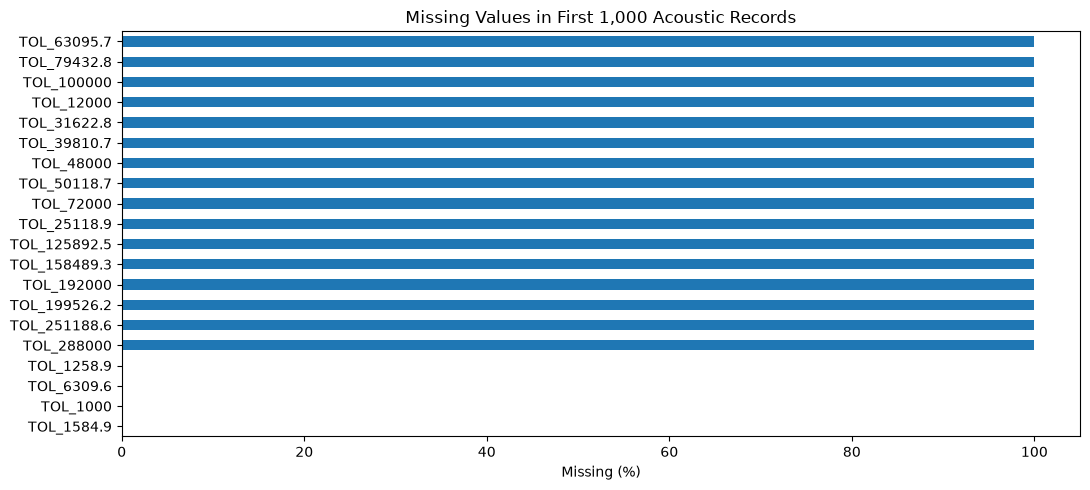

In [4]:
missing = (
    sample.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(
    missing.head(25).to_frame("missing_percent")
)

fig, ax = plt.subplots(figsize=(11, 5))

missing.head(20).sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Missing Values in First 1,000 Acoustic Records")
ax.set_xlabel("Missing (%)")

plt.tight_layout()
plt.show()


In [5]:
levels_db = np.array([60, 70, 80, 90], dtype=float)

relative_energy = 10 ** (levels_db / 10)

example = pd.DataFrame({
    "Level (dB)": levels_db,
    "Relative energy": relative_energy
})

example["Energy ratio to 60 dB"] = (
    example["Relative energy"] /
    example["Relative energy"].iloc[0]
)

display(example)


,Level (dB),Relative energy,Energy ratio to 60 dB
0,60.0,1.000000e+06,1.0
1,70.0,1.000000e+07,10.0
2,80.0,1.000000e+08,100.0
3,90.0,1.000000e+09,1000.0


## 2. Station Coverage & Missing Bands

- **Finding:** `1,715,779` rows span 10 sites, heavily skewed toward `01_Richards_Bay` (`58.35%`); extra raw `TOL_*` columns outside `31.6–7943.3 Hz` are mostly missing.
- **Choice driven:** Enforce station-balanced sampling (prevent Richards Bay dominance) and restrict features to the 25 active competition bands.


,file,rows,columns,band_columns,first_timestamp,last_timestamp,pct_missing_bands,rows_duration_under55,rows_duration_not60,recorders
0,acoustics/01_Richards_Bay.parquet,1001174,74,62,2017-05-09 00:00:02,2024-05-25 23:59:00,23.578,15691,27415,3
1,acoustics/02_Durban.parquet,44640,74,62,2025-10-28 00:00:00,2025-12-06 23:59:00,30.645,0,16,1
2,acoustics/03_Cape_Recife.parquet,5928,74,62,2024-03-05 00:00:00,2024-03-23 23:12:00,25.806,0,0,1
3,acoustics/04_Bird_Island.parquet,47552,74,62,2022-03-21 05:59:58,2024-06-29 23:59:00,30.718,32,60,2
4,acoustics/05_St_Croix_Island.parquet,250717,74,62,2022-04-05 00:00:00,2025-09-20 06:00:00,31.728,130,282,3
5,acoustics/06_Riy_Banks.parquet,4121,74,62,2024-03-05 00:00:00,2024-04-05 23:12:00,25.806,0,0,1
6,acoustics/07_St_Francis.parquet,169488,74,62,2015-04-21 00:00:00,2018-02-28 14:24:00,25.806,1,2,1
7,acoustics/09_Fish_Hoek.parquet,53767,74,62,2016-09-13 00:00:02,2021-09-28 12:45:00,21.373,1014,8296,2
8,acoustics/10_Sea_Point.parquet,3660,74,62,2018-10-11 10:00:02,2018-10-13 23:59:00,17.742,0,2,1
9,acoustics/13_Saldhana_Bay.parquet,134732,74,62,2022-03-22 00:00:00,2023-05-29 04:34:00,25.806,28,161,2


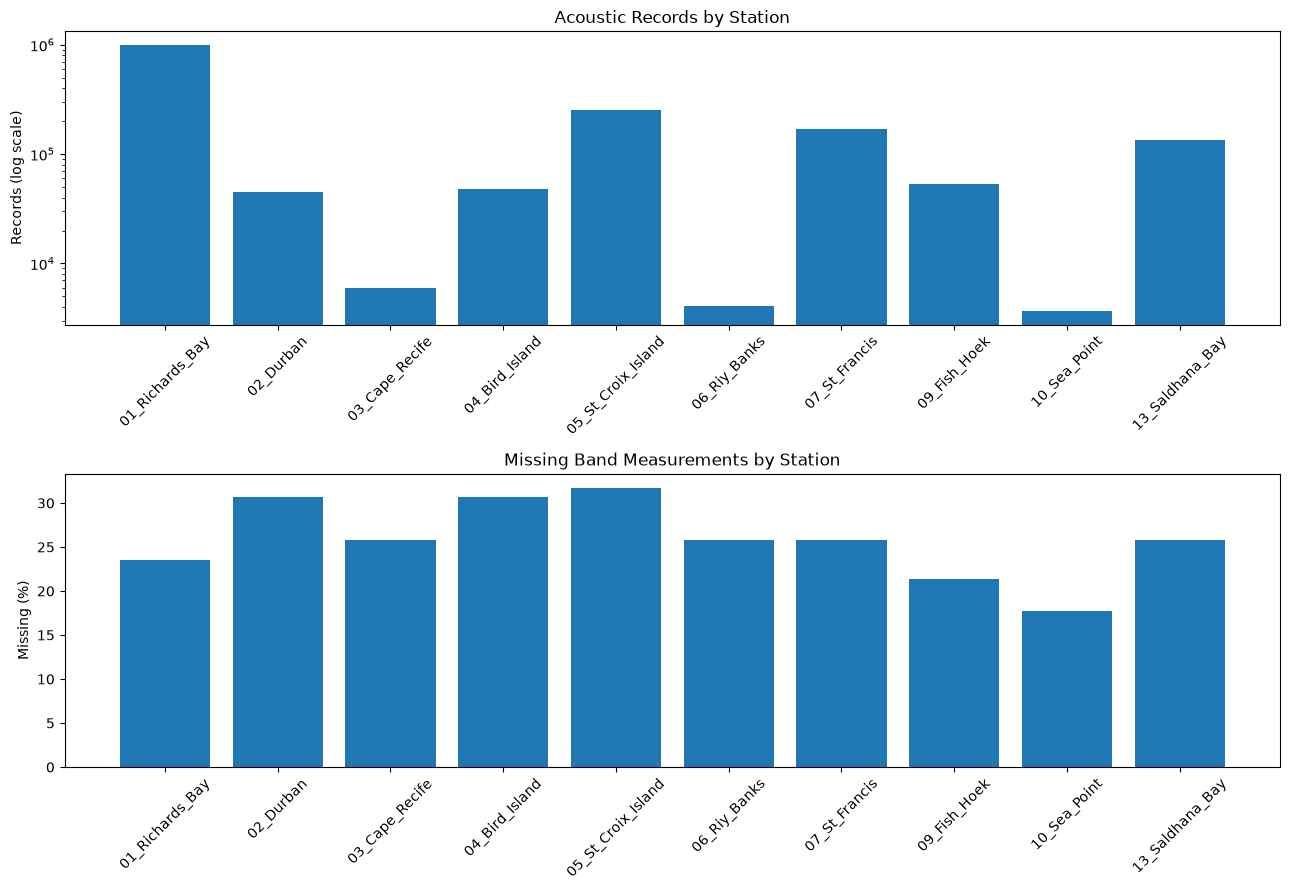

In [6]:
# Read the station-level audit we already generated.
audit_path = (
    PROJECT_ROOT
    / "reports"
    / "zindi_audit"
    / "station_acoustic_audit.csv"
)

station_audit = pd.read_csv(audit_path)

display(station_audit)

# Visualize station recording coverage.
station_audit["station"] = (
    station_audit["file"]
    .str.replace(".parquet", "", regex=False)
    .str.split("/")
    .str[-1]
)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Number of recordings per station.
axes[0].bar(
    station_audit["station"],
    station_audit["rows"]
)

axes[0].set_yscale("log")
axes[0].set_title("Acoustic Records by Station")
axes[0].set_ylabel("Records (log scale)")
axes[0].tick_params(axis="x", rotation=45)

# Missing acoustic band percentage.
axes[1].bar(
    station_audit["station"],
    station_audit["pct_missing_bands"]
)

axes[1].set_title("Missing Band Measurements by Station")
axes[1].set_ylabel("Missing (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [7]:
total_records = station_audit["rows"].sum()

station_audit["share_of_records_pct"] = (
    100 * station_audit["rows"] / total_records
)

summary = station_audit[
    ["station", "rows", "share_of_records_pct", "recorders"]
].sort_values("rows", ascending=False)

display(summary)

print(f"Total records: {total_records:,}")

print(
    "Largest station share:",
    f"{summary['share_of_records_pct'].iloc[0]:.2f}%"
)

,station,rows,share_of_records_pct,recorders
0,01_Richards_Bay,1001174,58.350988,3
4,05_St_Croix_Island,250717,14.612430,3
6,07_St_Francis,169488,9.878195,1
9,13_Saldhana_Bay,134732,7.852526,2
7,09_Fish_Hoek,53767,3.133679,2
3,04_Bird_Island,47552,2.771453,2
1,02_Durban,44640,2.601734,1
2,03_Cape_Recife,5928,0.345499,1
5,06_Riy_Banks,4121,0.240182,1
8,10_Sea_Point,3660,0.213314,1


Total records: 1,715,779
Largest station share: 58.35%


## 3. Competition 25-Band Schema Check

- **Finding:** All 25 competition third-octave columns exist across the station parquets with zero missing names.
- **Choice driven:** Lock canonical column order `TOL_31.6` .. `TOL_7943.3` identically across extraction, simulation, and `Test.csv` inference.


In [8]:
# Read only the CSV header: no test measurements are loaded.
test_path = PROJECT_ROOT / "data" / "zindi" / "raw" / "Test.csv"

test_columns = pd.read_csv(test_path, nrows=0).columns.tolist()

print("Total test columns:", len(test_columns))

feature_columns = [
    col for col in test_columns if col != "ID"
]

print("Acoustic features:", len(feature_columns))

print("\nFirst 20 features:")
print(feature_columns[:20])

print("\nLast 20 features:")
print(feature_columns[-20:])

Total test columns: 376
Acoustic features: 375

First 20 features:
['m01_TOL_31.6', 'm01_TOL_39.8', 'm01_TOL_50.1', 'm01_TOL_63.1', 'm01_TOL_79.4', 'm01_TOL_100', 'm01_TOL_125.9', 'm01_TOL_158.5', 'm01_TOL_199.5', 'm01_TOL_251.2', 'm01_TOL_316.2', 'm01_TOL_398.1', 'm01_TOL_501.2', 'm01_TOL_631', 'm01_TOL_794.3', 'm01_TOL_1000', 'm01_TOL_1258.9', 'm01_TOL_1584.9', 'm01_TOL_1995.3', 'm01_TOL_2511.9']

Last 20 features:
['m15_TOL_100', 'm15_TOL_125.9', 'm15_TOL_158.5', 'm15_TOL_199.5', 'm15_TOL_251.2', 'm15_TOL_316.2', 'm15_TOL_398.1', 'm15_TOL_501.2', 'm15_TOL_631', 'm15_TOL_794.3', 'm15_TOL_1000', 'm15_TOL_1258.9', 'm15_TOL_1584.9', 'm15_TOL_1995.3', 'm15_TOL_2511.9', 'm15_TOL_3162.3', 'm15_TOL_3981.1', 'm15_TOL_5011.9', 'm15_TOL_6309.6', 'm15_TOL_7943.3']


In [9]:
import re

# Extract possible frequency labels from test feature names.
frequencies = set()

for col in feature_columns:
    matches = re.findall(r"TOL_([0-9]+(?:\.[0-9]+)?)", col)
    frequencies.update(matches)

frequencies = sorted(frequencies, key=float)

print("Frequency bands discovered:", len(frequencies))
print(frequencies)


Frequency bands discovered: 25
['31.6', '39.8', '50.1', '63.1', '79.4', '100', '125.9', '158.5', '199.5', '251.2', '316.2', '398.1', '501.2', '631', '794.3', '1000', '1258.9', '1584.9', '1995.3', '2511.9', '3162.3', '3981.1', '5011.9', '6309.6', '7943.3']


In [10]:
archive_band_columns = [
    col for col in sample.columns
    if col.startswith("TOL_")
]

expected_band_columns = [
    f"TOL_{freq}" for freq in frequencies
]

available = [
    col for col in expected_band_columns
    if col in archive_band_columns
]

missing = [
    col for col in expected_band_columns
    if col not in archive_band_columns
]

print("Expected competition bands:", len(expected_band_columns))
print("Available in archive:", len(available))
print("Unavailable in archive:", missing)

Expected competition bands: 25
Available in archive: 25
Unavailable in archive: []


## 4. 25-Band Coverage Across Stations

- **Finding:** `100.00%` of raw rows in the South African archives contain complete, finite values across all 25 competition bands.
- **Choice driven:** Partial-band hardware dropouts do not happen in SA telemetry; `Test.csv` missingness comes solely from dropped whole minutes.


In [11]:
# Analyze the exact 25 competition bands across all stations.
# Process one Parquet batch at a time to limit memory use.

band_columns = expected_band_columns

coverage_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)
    total = 0
    valid_counts = np.zeros(len(band_columns), dtype=np.int64)

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas()[band_columns].to_numpy(
            dtype=np.float64
        )

        valid_counts += np.isfinite(values).sum(axis=0)
        total += values.shape[0]

    for band, valid_count in zip(
        band_columns, valid_counts
    ):
        coverage_records.append({
            "station": file.stem,
            "band": band,
            "total_rows": total,
            "valid_rows": int(valid_count),
            "coverage_pct": (
                100 * valid_count / total if total else np.nan
            )
        })

coverage_df = pd.DataFrame(coverage_records)

coverage_matrix = coverage_df.pivot(
    index="station",
    columns="band",
    values="coverage_pct"
)[band_columns]

display(coverage_matrix.round(2))

band,TOL_31.6,TOL_39.8,TOL_50.1,TOL_63.1,TOL_79.4,TOL_100,TOL_125.9,TOL_158.5,TOL_199.5,TOL_251.2,...,TOL_1000,TOL_1258.9,TOL_1584.9,TOL_1995.3,TOL_2511.9,TOL_3162.3,TOL_3981.1,TOL_5011.9,TOL_6309.6,TOL_7943.3
station,,,,,,,,,,,,,,,,,,,,,
01_Richards_Bay,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
02_Durban,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
03_Cape_Recife,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
04_Bird_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
05_St_Croix_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
06_Riy_Banks,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
07_St_Francis,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
09_Fish_Hoek,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
10_Sea_Point,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


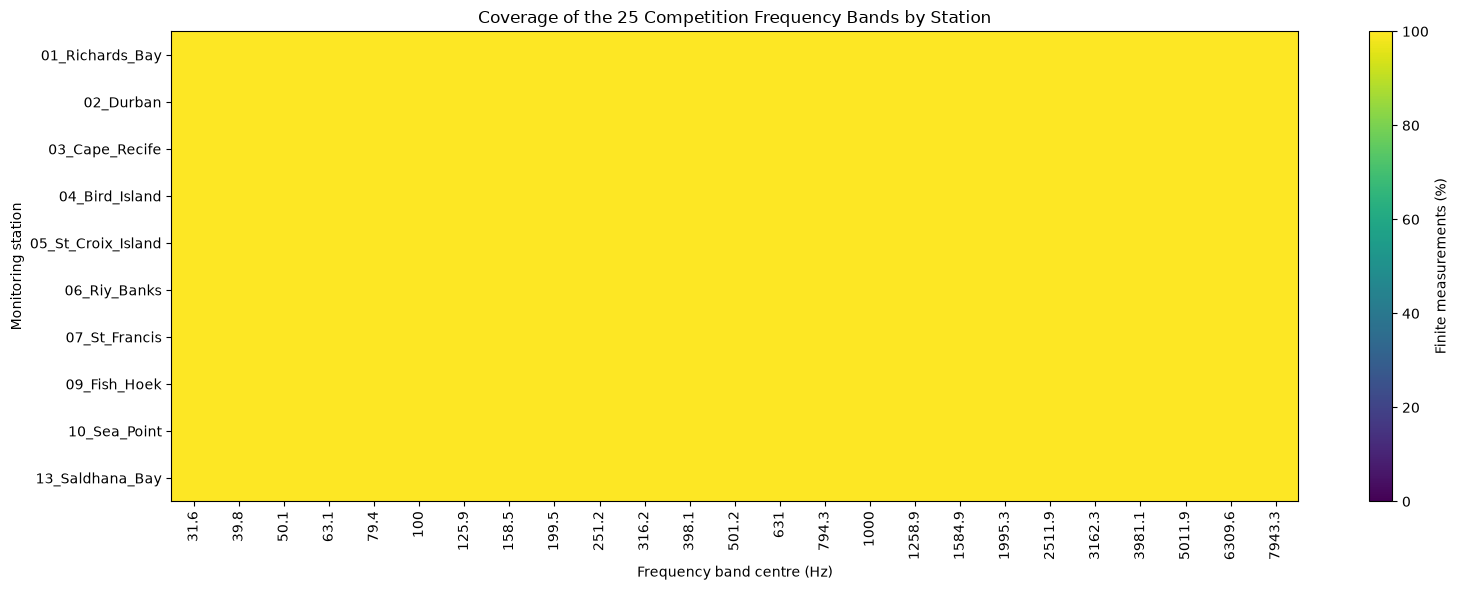

In [12]:
fig, ax = plt.subplots(figsize=(16, 6))

im = ax.imshow(
    coverage_matrix.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="viridis"
)

ax.set_xticks(range(len(band_columns)))
ax.set_xticklabels(
    [b.replace("TOL_", "") for b in band_columns],
    rotation=90
)

ax.set_yticks(range(len(coverage_matrix)))
ax.set_yticklabels(coverage_matrix.index)

ax.set_title(
    "Coverage of the 25 Competition Frequency Bands by Station"
)
ax.set_xlabel("Frequency band centre (Hz)")
ax.set_ylabel("Monitoring station")

fig.colorbar(im, ax=ax, label="Finite measurements (%)")

plt.tight_layout()
plt.show()


In [13]:
complete_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)

    total_rows = 0
    complete_rows = 0

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas().to_numpy(
            dtype=np.float64
        )

        finite = np.isfinite(values)

        total_rows += len(values)
        complete_rows += finite.all(axis=1).sum()

    complete_records.append({
        "station": file.stem,
        "total_rows": total_rows,
        "complete_25_band_rows": int(complete_rows),
        "complete_pct": (
            100 * complete_rows / total_rows
            if total_rows else np.nan
        )
    })

complete_df = pd.DataFrame(complete_records)

display(
    complete_df.sort_values(
        "complete_pct",
        ascending=False
    )
)

print(
    "Overall complete 25-band coverage:",
    f"{100 * complete_df['complete_25_band_rows'].sum() / complete_df['total_rows'].sum():.2f}%"
)


,station,total_rows,complete_25_band_rows,complete_pct
0,01_Richards_Bay,1001174,1001174,100.0
1,02_Durban,44640,44640,100.0
2,03_Cape_Recife,5928,5928,100.0
3,04_Bird_Island,47552,47552,100.0
4,05_St_Croix_Island,250717,250717,100.0
5,06_Riy_Banks,4121,4121,100.0
6,07_St_Francis,169488,169488,100.0
7,09_Fish_Hoek,53767,53767,100.0
8,10_Sea_Point,3660,3660,100.0
9,13_Saldhana_Bay,134732,134732,100.0


Overall complete 25-band coverage: 100.00%


## 5. Temporal Continuity & 15-Minute Window Availability

- **Finding:** Zero duplicate timestamps exist, yielding `88,143` non-overlapping continuous 15-minute windows across 8 stations.
- **Choice driven:** Slice `(15, 25)` matrices strictly inside unbroken runs (`never stitch across timestamp gaps`).


In [14]:
# Analyze temporal continuity without loading acoustic band values.
# Only timestamps, recorder IDs and durations are read.

continuity_records = []

for file in parquet_files:
    station = file.stem

    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"])

    station_valid_windows = 0
    station_continuous_runs = 0
    station_duplicates = 0
    station_short_duration = 0
    station_max_run = 0

    for recorder, group in df.groupby("recorder"):
        group = group.sort_values("t").reset_index(drop=True)

        duplicate = group["t"].duplicated(keep=False)
        station_duplicates += int(duplicate.sum())

        # Use only full or nearly full minute measurements.
        valid_duration = (
            group["dur"].ge(55)
            & group["dur"].le(65)
        )

        station_short_duration += int(
            (~valid_duration).sum()
        )

        # Allow small timestamp offsets caused by exports.
        delta_seconds = group["t"].diff().dt.total_seconds()

        continuous_edge = delta_seconds.between(
            58, 62, inclusive="both"
        )

        # Separate runs at timestamp gaps, invalid durations
        # and duplicate timestamps.
        previous_valid = valid_duration.shift(
            1, fill_value=False
        )

        run_start = ~(
            continuous_edge
            & valid_duration
            & previous_valid
            & ~duplicate
            & ~duplicate.shift(1, fill_value=False)
        )

        run_id = run_start.cumsum()

        valid_group = group.loc[
            valid_duration & ~duplicate
        ].copy()

        valid_group["run_id"] = run_id.loc[
            valid_duration & ~duplicate
        ].to_numpy()

        run_lengths = valid_group.groupby("run_id").size()

        station_continuous_runs += len(run_lengths)

        if len(run_lengths):
            station_max_run = max(
                station_max_run,
                int(run_lengths.max())
            )

            # Conservative, non-overlapping 15-minute windows.
            station_valid_windows += int(
                (run_lengths // 15).sum()
            )

    continuity_records.append({
        "station": station,
        "records": len(df),
        "duplicate_timestamp_rows": station_duplicates,
        "invalid_duration_rows": station_short_duration,
        "continuous_runs": station_continuous_runs,
        "longest_run_minutes": station_max_run,
        "nonoverlapping_15min_windows": station_valid_windows
    })

continuity_df = pd.DataFrame(continuity_records)

display(
    continuity_df.sort_values(
        "nonoverlapping_15min_windows",
        ascending=False
    )
)

print(
    "Total candidate non-overlapping windows:",
    f"{continuity_df['nonoverlapping_15min_windows'].sum():,}"
)

,station,records,duplicate_timestamp_rows,invalid_duration_rows,continuous_runs,longest_run_minutes,nonoverlapping_15min_windows
0,01_Richards_Bay,1001174,0,15713,15045,9664,52522
4,05_St_Croix_Island,250717,0,130,137,83040,16697
9,13_Saldhana_Bay,134732,0,28,303,1139,8868
6,07_St_Francis,169488,0,1,27154,15,3371
3,04_Bird_Island,47552,0,32,36,1440,3168
1,02_Durban,44640,0,0,2,37440,2976
7,09_Fish_Hoek,53767,0,1014,9765,1079,297
8,10_Sea_Point,3660,0,0,2,3300,244
2,03_Cape_Recife,5928,0,0,456,13,0
5,06_Riy_Banks,4121,0,0,317,13,0


Total candidate non-overlapping windows: 88,143


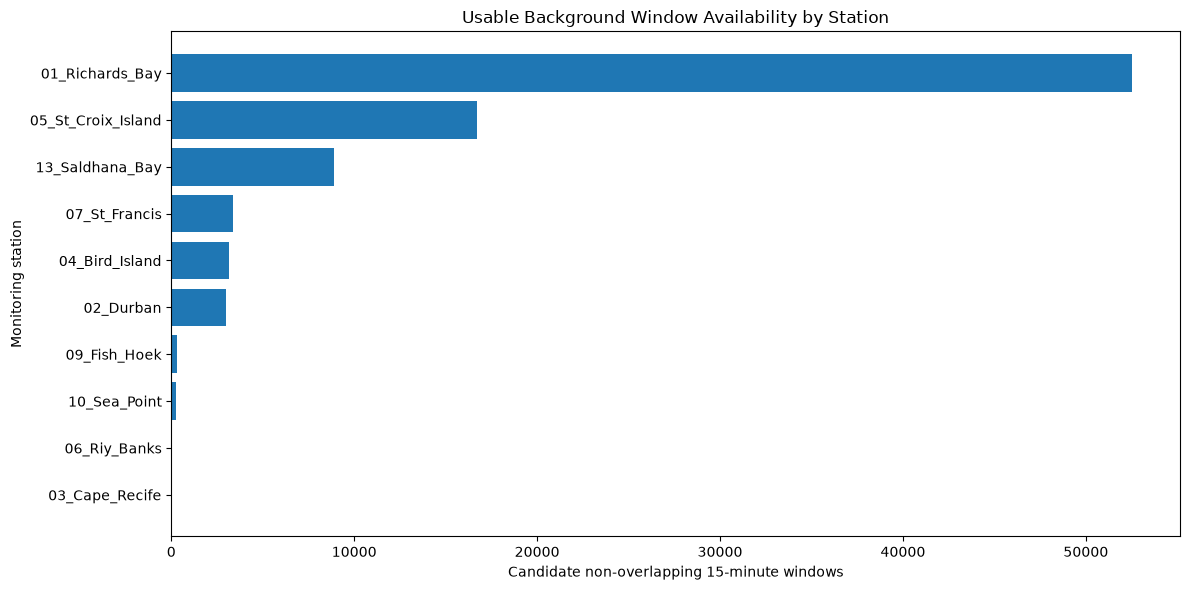

In [15]:
plot_df = continuity_df.sort_values(
    "nonoverlapping_15min_windows",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    plot_df["station"],
    plot_df["nonoverlapping_15min_windows"]
)

ax.set_xlabel("Candidate non-overlapping 15-minute windows")
ax.set_ylabel("Monitoring station")
ax.set_title("Usable Background Window Availability by Station")

plt.tight_layout()
plt.show()

In [16]:
output_path = REPORT_DIR / "temporal_continuity_summary.csv"

continuity_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge/reports/eda/temporal_continuity_summary.csv


## 6. Recording Interval Diagnostics

- **Finding:** `17` recorder configurations vary widely in cadence (`1–360 s`) and source-export dB baseline offsets without physical hydrophone calibration.
- **Choice driven:** Prohibit raw uncentered dB across sites; engineer strictly global-offset-invariant features (`X - median(X)`).


In [17]:
# Diagnose timestamp spacing and recording durations.
# Read metadata only; do not load acoustic measurements.

diagnostic_rows = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")

    for recorder, group in df.groupby("recorder", dropna=False):
        group = group.sort_values("t")

        delta = (
            group["t"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        duration = pd.to_numeric(
            group["dur"], errors="coerce"
        )

        # Inspect the most common rounded timestamp intervals.
        common_intervals = (
            delta.round()
            .value_counts()
            .head(5)
        )

        diagnostic_rows.append({
            "station": file.stem,
            "recorder": str(recorder),
            "records": len(group),
            "median_interval_sec": delta.median(),
            "pct_intervals_58_62": (
                100 * delta.between(58, 62).mean()
                if len(delta) else np.nan
            ),
            "pct_intervals_55_65": (
                100 * delta.between(55, 65).mean()
                if len(delta) else np.nan
            ),
            "median_duration_sec": duration.median(),
            "duration_min_sec": duration.min(),
            "duration_max_sec": duration.max(),
            "common_intervals_sec": ", ".join(
                f"{interval:g}s:{count}"
                for interval, count in common_intervals.items()
            )
        })

interval_df = pd.DataFrame(diagnostic_rows)

display(
    interval_df.sort_values(
        ["station", "recorder"]
    )
)

interval_df.to_csv(
    REPORT_DIR / "recorder_interval_diagnostics.csv",
    index=False
)

print("Recorder configurations:", len(interval_df))

,station,recorder,records,median_interval_sec,pct_intervals_58_62,pct_intervals_55_65,median_duration_sec,duration_min_sec,duration_max_sec,common_intervals_sec
0,01_Richards_Bay,201383949_Richards_Bay_201383949.1.24000,492310,60.0,99.746704,99.753204,60.0,1.0,360.0,"60s:480468, 58s:5331, 62s:5251, 29s:392, 91s:391"
1,01_Richards_Bay,5708_Richards_Bay_5708.1.24000,160798,60.0,97.754311,97.962027,60.0,1.0,71.0,"60s:156363, 120s:754, 58s:400, 62s:393, 45s:117"
2,01_Richards_Bay,7005_Richards_Bay_7005.1.24000,348066,60.0,96.753767,96.972405,60.0,2.0,60.0,"60s:336467, 2s:4825, 118s:4822, 89s:426, 31s:426"
3,02_Durban,8230_ST600_8230.1.48000,44640,60.0,99.997760,99.997760,60.0,59.0,60.0,"60s:44632, 61s:3, 59s:3, 777660s:1"
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,92.323266,60.0,60.0,60.0,"60s:5472, 2880s:455"
5,04_Bird_Island,URN.BirdIsland.2022_6509.1.24000,46472,60.0,99.857976,99.857976,60.0,2.0,60.0,"60s:46405, 2s:32, 86458s:27, 842460s:3, 1.0368..."
6,04_Bird_Island,URN_8321_8321.1.12000,1080,60.0,100.000000,100.000000,60.0,58.0,60.0,60s:1079
7,05_St_Croix_Island,URN.BirdIsland.2022_6509.1.24000,45163,60.0,99.869359,99.869359,60.0,2.0,60.0,"60s:45097, 2s:26, 86458s:23, 86402s:6, 58s:6"
8,05_St_Croix_Island,URN.StCroix.2022_6509.1.24000,70116,60.0,99.864508,99.864508,60.0,2.0,60.0,"60s:70013, 2s:43, 86458s:38, 58s:7, 86402s:6"
9,05_St_Croix_Island,URN_8321_8321.1.12000,135438,60.0,99.960129,99.964559,60.0,2.0,60.0,"60s:135353, 58s:30, 86402s:26, 86403s:6, 57s:6"


Recorder configurations: 17


In [18]:
suspicious = interval_df[
    interval_df["station"].str.contains(
        "Cape_Recife|Riy_Banks|St_Francis|Fish_Hoek",
        regex=True
    )
]

display(
    suspicious[
        [
            "station",
            "recorder",
            "records",
            "median_interval_sec",
            "pct_intervals_58_62",
            "median_duration_sec",
            "common_intervals_sec"
        ]
    ]
)

,station,recorder,records,median_interval_sec,pct_intervals_58_62,median_duration_sec,common_intervals_sec
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,60.0,"60s:5472, 2880s:455"
10,06_Riy_Banks,8230_ST600_8230.1.48000,4121,60.0,92.330097,60.0,"60s:3804, 2880s:296, 6480s:17, 780480s:2, 1008..."
11,07_St_Francis,SM2M_Cape_StFrancis_SM2M.1.48000,169488,60.0,83.979302,60.0,"60s:142334, 960s:23759, 2760s:3362, 778560s:10..."
12,09_Fish_Hoek,ST300_201650217_ST201650217.1.96000,49260,60.0,79.179439,60.0,"60s:32149, 58s:6852, 362s:6840, 360s:2383, 49s..."
13,09_Fish_Hoek,ST300_5344_ST5344.1.96000,4507,60.0,99.800266,60.0,"60s:4491, 120s:5, 61s:3, 59s:3, 25s:2"


## 7. Continuous Run-Length Distributions

- **Finding:** `03_Cape_Recife` and `06_Riy_Banks` have max continuous run length `< 15` minutes (`0` complete 15-minute windows).
- **Choice driven:** Exclude Cape Recife and Riy Banks cleanly from window simulation pools.


In [19]:
# Summarize continuous run lengths by station.
# No acoustic measurements or test labels are loaded.

run_summaries = []
run_details = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")
    df["dur"] = pd.to_numeric(df["dur"], errors="coerce")

    for recorder, group in df.groupby(
        "recorder", dropna=False
    ):
        group = group.sort_values("t").reset_index(drop=True)

        valid = group["t"].notna() & group["dur"].between(
            55, 65
        )

        duplicate = group["t"].duplicated(keep=False)
        valid = valid & ~duplicate

        delta = group["t"].diff().dt.total_seconds()

        # A run continues only across a valid 58–62 s step.
        continues = (
            delta.between(58, 62)
            & valid
            & valid.shift(1, fill_value=False)
        )

        run_id = (~continues).cumsum()

        good = group.loc[valid].copy()
        good["run_id"] = run_id.loc[valid].to_numpy()

        lengths = good.groupby("run_id").size()

        for length, count in lengths.value_counts().items():
            run_details.append({
                "station": file.stem,
                "recorder": str(recorder),
                "run_length_minutes": int(length),
                "number_of_runs": int(count)
            })

        run_summaries.append({
            "station": file.stem,
            "recorder": str(recorder),
            "runs": len(lengths),
            "runs_13_or_more": int((lengths >= 13).sum()),
            "runs_15_or_more": int((lengths >= 15).sum()),
            "candidate_full_windows": int(
                (lengths // 15).sum()
            ),
            "maximum_run": (
                int(lengths.max()) if len(lengths) else 0
            )
        })

run_summary_df = pd.DataFrame(run_summaries)
run_length_df = pd.DataFrame(run_details)

station_run_summary = (
    run_summary_df
    .groupby("station", as_index=False)
    .agg({
        "runs": "sum",
        "runs_13_or_more": "sum",
        "runs_15_or_more": "sum",
        "candidate_full_windows": "sum",
        "maximum_run": "max"
    })
)

display(station_run_summary)

print(
    "Total candidate full windows:",
    station_run_summary["candidate_full_windows"].sum()
)


,station,runs,runs_13_or_more,runs_15_or_more,candidate_full_windows,maximum_run
0,01_Richards_Bay,15045,14324,14318,52522,9664
1,02_Durban,2,2,2,2976,37440
2,03_Cape_Recife,456,456,0,0,13
3,04_Bird_Island,36,36,36,3168,1440
4,05_St_Croix_Island,137,131,131,16697,83040
5,06_Riy_Banks,317,317,0,0,13
6,07_St_Francis,27154,3371,3371,3371,15
7,09_Fish_Hoek,9765,8,8,297,1079
8,10_Sea_Point,2,2,2,244,3300
9,13_Saldhana_Bay,303,301,301,8868,1139


Total candidate full windows: 88143


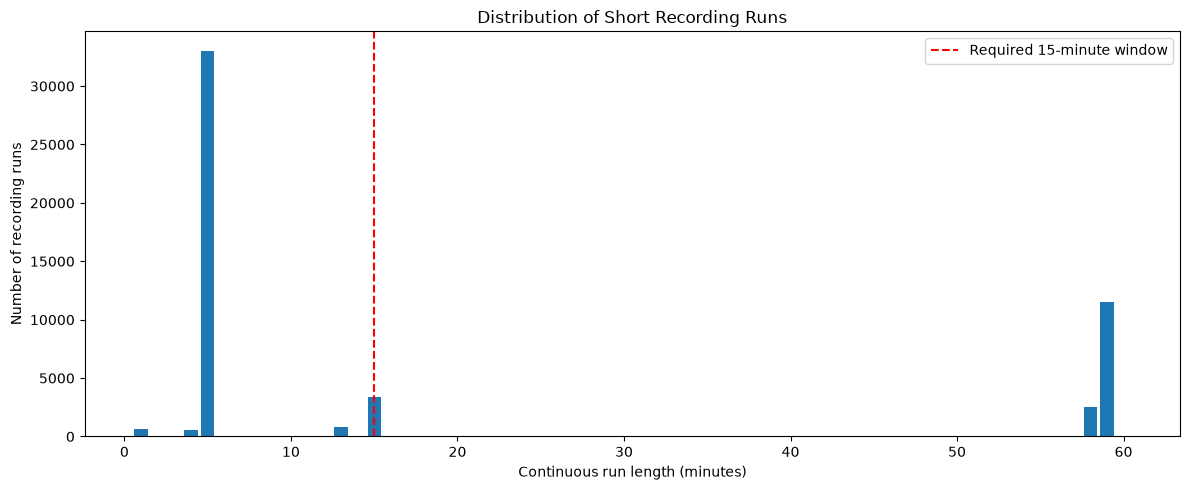

In [20]:
run_distribution = (
    run_length_df.loc[
        run_length_df["run_length_minutes"] <= 60
    ]
    .groupby("run_length_minutes")["number_of_runs"]
    .sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    run_distribution.index,
    run_distribution.values
)

ax.axvline(
    15, linestyle="--", color="red",
    label="Required 15-minute window"
)

ax.set_xlabel("Continuous run length (minutes)")
ax.set_ylabel("Number of recording runs")
ax.set_title("Distribution of Short Recording Runs")
ax.legend()

plt.tight_layout()
plt.show()

In [21]:
station_run_summary.to_csv(
    REPORT_DIR / "station_run_length_summary.csv",
    index=False
)

run_length_df.to_csv(
    REPORT_DIR / "recorder_run_length_distribution.csv",
    index=False
)

print("Run-length analysis saved.")

Run-length analysis saved.


---
# Part II — Splits, VTUAD Extraction & Synthetic Experiment Decisions

Structured experimental evidence diagnosing V1 baseline limits and locking the physics and validation choices for Notebook 02.


In [22]:
# Shared paths and helper functions for the new lessons.
# All new checks use local reports; no competition test feature values are read.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EDA = PROJECT_ROOT / "reports" / "eda"
SYNTH = EDA / "synthetic_v1"

def report_path(name):
    path = EDA / name
    if not path.exists():
        print(f"Not available yet: {path} (run the corresponding script first)")
        return None
    return path

print("Project root:", PROJECT_ROOT)
print("Available results:")
for name in [
    "background_window_index.csv",
    "background_split_manifest_v2.csv",
    "vtuad_metadata_reconciliation.csv",
    "vtuad_source_split_v1.csv",
    "vtuad_source_split_v2.csv",
    "vtuad_minute_band_power_split_v2.csv",
]:
    print(" ", name, (EDA / name).exists())
print("Synthetic files present:", (SYNTH / "train.npz").exists(),
      (SYNTH / "validation.npz").exists())

Project root: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge
Available results:
  background_window_index.csv True
  background_split_manifest_v2.csv True
  vtuad_metadata_reconciliation.csv True
  vtuad_source_split_v1.csv True
  vtuad_source_split_v2.csv True
  vtuad_minute_band_power_split_v2.csv True
Synthetic files present: True True


## 8. 15-Minute Background Window Index

- **Finding:** Window supply spans `52,522` (`Richards_Bay`) down to `297` (`Fish_Hoek`) and `244` (`Sea_Point`) across `18,169` continuous runs.
- **Choice driven:** Equalize background representation per station inside `train` (`6,000`) and `val` (`1,500`).


In [23]:
p = report_path("background_window_index.csv")
if p is not None:
    index = pd.read_csv(p, usecols=["station", "run_id", "start_time"])
    print("Indexed windows:", len(index))
    print("Stations:", index.station.nunique())
    print("Continuous recording runs:", index.run_id.nunique())
    display(index.groupby("station").size().sort_values(ascending=False)
            .rename("windows").to_frame())
    assert len(index) == 88143

Indexed windows: 88143
Stations: 8
Continuous recording runs: 18169


,windows
station,
01_Richards_Bay,52522
05_St_Croix_Island,16697
13_Saldhana_Bay,8868
07_St_Francis,3371
04_Bird_Island,3168
02_Durban,2976
09_Fish_Hoek,297
10_Sea_Point,244


## 9. Chronological & Run-Isolated Background Split (v2)

- **Finding:** Run-grouped splitting with 9–49 day chronological gaps leaves `67,463` train / `16,946` val / `3,193` excluded, plus `541` untouched `station_holdout` windows (`Fish_Hoek`, `Sea_Point`).
- **Choice driven:** Evaluate every candidate model on both in-station `val` and completely unseen `station_holdout` stations.


,windows
split,
train,67463
validation,16946
excluded,3193
station_holdout,541


split,excluded,station_holdout,train,validation
station,,,,
01_Richards_Bay,777,0,41691,10054
02_Durban,0,0,480,2496
04_Bird_Island,384,0,2472,312
05_St_Croix_Island,408,0,13935,2354
07_St_Francis,216,0,2630,525
09_Fish_Hoek,0,297,0,0
10_Sea_Point,0,244,0,0
13_Saldhana_Bay,1408,0,6255,1205


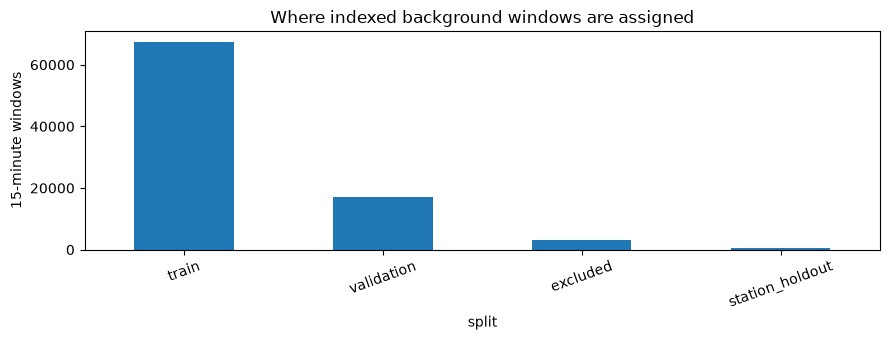

In [24]:
p = report_path("background_split_manifest_v2.csv")
if p is not None:
    bg_split = pd.read_csv(p, usecols=["station", "run_id", "split", "start_time", "last_start_time"])
    counts = bg_split["split"].value_counts()
    display(counts.rename("windows").to_frame())
    display(pd.crosstab(bg_split.station, bg_split.split))
    assert len(bg_split) == 88143
    assert counts.to_dict() == {"train": 67463, "validation": 16946,
                                "excluded": 3193, "station_holdout": 541}
    assert bg_split.groupby("run_id")["split"].nunique().max() == 1
    fig, ax = plt.subplots(figsize=(9, 3.5))
    counts.reindex(["train", "validation", "excluded", "station_holdout"]).plot.bar(ax=ax)
    ax.set_title("Where indexed background windows are assigned")
    ax.set_ylabel("15-minute windows")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

## 10. VTUAD v1.3.0 Verification & Metadata Audit

- **Finding:** All `525` WAVs passed SHA-256 checks, `22` files stored inside `vessel/` are actually `background`, and `167` WAV durations differ `> 60 s` from metadata.
- **Choice driven:** Filter strictly by verified metadata `label != 'background'` and read exact WAV frames rather than trusting folders or durations.


In [25]:
p = report_path("vtuad_metadata_reconciliation.csv")
if p is not None:
    reconcile = pd.read_csv(p)
    print("Metadata records:", len(reconcile))
    print("WAV files found:", int(reconcile.exists.sum()))
    print("Labels versus directory:")
    display(pd.crosstab(reconcile.directory_category, reconcile.label))
    durations = (reconcile.wav_duration - reconcile.metadata_duration).abs()
    print("Duration matches (<0.01 s):", int((durations < 0.01).sum()))
    print("Duration difference >60 s:", int((durations > 60).sum()))
    assert len(reconcile) == 525 and reconcile.exists.all()

Metadata records: 525
WAV files found: 525
Labels versus directory:


label,background,cargo,dredger,fishing,other,passengership,pilotvessel,pleasurecraft,rescue,sailing,tanker,tug
directory_category,,,,,,,,,,,,
background,16,0,0,0,0,0,0,0,0,0,0,0
vessel,22,97,8,34,40,71,2,32,4,6,5,188


Duration matches (<0.01 s): 353
Duration difference >60 s: 167


## 11. Hull-Disjoint Vessel Source Split (v2)

- **Finding:** Grouping by `hull_id` yields zero overlap between `train` (`410` clips, `137` hulls) and `validation` (`77` clips, `35` hulls), isolating `38` background references.
- **Choice driven:** Enforce zero `bg_run_id` and zero `hull_id` / `vessel_group` overlap across CV folds, `val`, and `holdout`.


In [26]:
p = report_path("vtuad_source_split_v2.csv")
if p is not None:
    vessel_split = pd.read_csv(p, dtype={"hull_id": "string"})
    display(pd.crosstab(vessel_split.label, vessel_split.source_split))
    active = vessel_split[vessel_split.source_split.isin(["train", "validation"])]
    print("Clips by split:", active.source_split.value_counts().to_dict())
    print("Unique hulls:", active.groupby("source_split").hull_id.nunique().to_dict())
    assert len(vessel_split) == 525 and len(active) == 487
    assert active.groupby("hull_id").source_split.nunique().max() == 1
    assert set(active.loc[active.source_split.eq("train"), "hull_id"]).isdisjoint(
        set(active.loc[active.source_split.eq("validation"), "hull_id"]))
    print("Hull overlap: 0 — PASS")

source_split,background_reference,train,validation
label,,,
background,38,0,0
cargo,0,88,9
dredger,0,8,0
fishing,0,29,5
other,0,37,3
passengership,0,65,6
pilotvessel,0,2,0
pleasurecraft,0,27,5
rescue,0,3,1


Clips by split: {'train': 410, 'validation': 77}
Unique hulls: {'train': 137, 'validation': 35}
Hull overlap: 0 — PASS


## 12. VTUAD 25-Band Relative Power Extraction

- **Finding:** Welch (`nperseg=32768`, `2^(1/6)` base-2 edges) extracted `1,892` vessel minutes (`49%` `tug`, zero small coastal craft).
- **Choice driven:** Upgrade extraction to starter-matched 2s Hann deci-decade (`10^0.05` base-10) and add `96` HearMyShip coastal craft WAVs across `8` classes.


Minute rows: 1892
Source clips: 487
Band count: 25


source_split,train,validation
label,,
cargo,252,33
dredger,18,0
fishing,133,34
other,129,8
passengership,157,16
pilotvessel,4,0
pleasurecraft,95,22
rescue,25,3
sailing,20,4


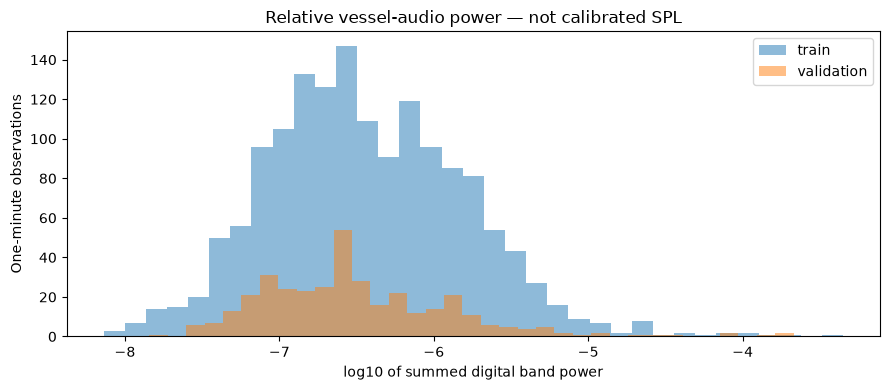

Vessel feature checks: PASS


In [27]:
p = report_path("vtuad_minute_band_power_split_v2.csv")
if p is not None:
    vessel_features = pd.read_csv(p, dtype={"hull_id": "string"})
    vessel_bands = [c for c in vessel_features if c.startswith("TOL_")]
    print("Minute rows:", len(vessel_features))
    print("Source clips:", vessel_features.clip_uid.nunique())
    print("Band count:", len(vessel_bands))
    display(pd.crosstab(vessel_features.label, vessel_features.source_split))
    assert len(vessel_features) == 1892
    assert vessel_features.clip_uid.nunique() == 487
    assert len(vessel_bands) == 25
    power = vessel_features[vessel_bands].to_numpy(dtype=float)
    assert np.isfinite(power).all() and (power >= 0).all()
    assert np.allclose(power.sum(axis=1), vessel_features.relative_total_power,
                       rtol=1e-9, atol=1e-15)
    assert not vessel_features.duplicated(["clip_uid", "minute_index"]).any()
    fig, ax = plt.subplots(figsize=(9, 4))
    for split, group in vessel_features.groupby("source_split"):
        ax.hist(np.log10(group.relative_total_power), bins=35, alpha=0.5,
                label=split)
    ax.set_xlabel("log10 of summed digital band power")
    ax.set_ylabel("One-minute observations")
    ax.set_title("Relative vessel-audio power — not calibrated SPL")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print("Vessel feature checks: PASS")

## 13. Synthetic Experiment 001 (Discrete Target Shares)

- **Finding:** Exp 001 (`200/80` windows, discrete shares `0–0.70`) subtracted per-window `max(background_db)`, warping ambient levels.
- **Choice driven:** Establish controlled Exp 001 baseline before scaling features or data.


In [28]:
# Inspect generated arrays without rebuilding them.
# IMPORTANT: X contains logarithmic relative acoustic levels (10*log10(energy)),
# not nonnegative linear energy. Negative X values are valid.
for split, expected_n in [("train", 200), ("validation", 80)]:
    p = SYNTH / f"{split}.npz"
    if not p.exists():
        print(f"Not available yet: {p}")
        continue

    with np.load(p, allow_pickle=False) as archive:
        print(f"{split}: available keys = {archive.files}")
        assert {"X", "y"}.issubset(archive.files)
        X, y = archive["X"], archive["y"]
        print("  X shape:", X.shape, "y shape:", y.shape)
        print("  Log-level range:", float(X.min()), "to", float(X.max()))
        print("  Target range:", float(y.min()), "to", float(y.max()))
        print("  Target average:", float(y.mean()))

        assert X.shape == (expected_n, 15, 25)
        assert y.shape == (expected_n,)
        assert np.issubdtype(X.dtype, np.floating)
        assert np.isfinite(X).all() and np.isfinite(y).all()
        # Logarithmic values may legitimately be negative. Converting back to
        # relative linear energy must produce finite, strictly positive values.
        linear_energy = np.power(10.0, X.astype(np.float64) / 10.0)
        assert np.isfinite(linear_energy).all()
        assert (linear_energy > 0).all()
        assert ((y >= 0) & (y < 1)).all()
        print("  Negative log-level cells (valid):", int((X < 0).sum()))
        print("  Zero-addition targets:", int((y == 0).sum()))

    csv_path = SYNTH / f"{split}_provenance.csv"
    if csv_path.exists():
        trace = pd.read_csv(csv_path)
        print("  Provenance records:", len(trace))
        print("  Provenance columns:", trace.columns.tolist())
        display(trace.head(3))
        assert len(trace) == expected_n
        if {"requested_share", "recovered_share"}.issubset(trace.columns):
            requested = trace["requested_share"].to_numpy(dtype=float)
            recovered = trace["recovered_share"].to_numpy(dtype=float)
            assert np.allclose(requested, recovered, atol=1e-10)
            assert np.allclose(y, recovered, atol=1e-6)
    print()

print("Synthetic file audit: PASS (log-level representation validated).")
print("These are simulated targets, not competition labels.")

train: available keys = ['X', 'y']
  X shape: (200, 15, 25) y shape: (200,)
  Log-level range: -113.0 to 11.775837898254395
  Target range: 0.0 to 0.699999988079071
  Target average: 0.28075000643730164
  Negative log-level cells (valid): 74093
  Zero-addition targets: 34
  Provenance records: 200
  Provenance columns: ['example', 'partition', 'station', 'background_run_id', 'background_start', 'background_source', 'vessel_clip_uid', 'vessel_hull_id', 'vessel_class', 'vessel_duration_min', 'vessel_audio_start_min', 'inserted_start_min', 'requested_share', 'recovered_share', 'relative_scale']


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,train,01_Richards_Bay,01_Richards_Bay|201383949_Richards_Bay_2013839...,2019-09-05 15:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-07-31 17:15:00,data/zindi/extracted/acoustics/01_Richards_Bay...,4ff2004f178bdd65,H071,rescue,14,0,1,0.05,0.05,1.272376e+05
2,2,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-05-05 16:08:00,data/zindi/extracted/acoustics/01_Richards_Bay...,c9895bb272520c0e,H027,passengership,2,0,4,0.15,0.15,1.432925e+06



validation: available keys = ['X', 'y']
  X shape: (80, 15, 25) y shape: (80,)
  Log-level range: -63.099998474121094 to 11.737883567810059
  Target range: 0.0 to 0.699999988079071
  Target average: 0.27687495946884155
  Negative log-level cells (valid): 29641
  Zero-addition targets: 14
  Provenance records: 80
  Provenance columns: ['example', 'partition', 'station', 'background_run_id', 'background_start', 'background_source', 'vessel_clip_uid', 'vessel_hull_id', 'vessel_class', 'vessel_duration_min', 'vessel_audio_start_min', 'inserted_start_min', 'requested_share', 'recovered_share', 'relative_scale']


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 14:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 06:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,159579b2f17cefa6,H122,passengership,2,0,9,0.05,0.05,1.786910e+06
2,2,validation,02_Durban,02_Durban|8230_ST600_8230.1.48000|2,2025-12-04 16:30:00,data/zindi/extracted/acoustics/02_Durban.parquet,830e7eb1ef1c5601,H176,other,3,0,12,0.15,0.15,1.618181e+06



Synthetic file audit: PASS (log-level representation validated).
These are simulated targets, not competition labels.


## 14. Experiment 001 Baseline Check

- **Finding:** Raw 375-feature RF beat Constant Mean (`0.197845` vs `0.249648` RMSE), whereas unscaled `ridge_alpha_10` degraded (`0.266875`).
- **Choice driven:** Standardize regularized linear models and replace high-variance raw 375 grids with structured summary features.


## 15. Experiment 001 Provenance Inspection

- **Finding:** Exp 001 inherited Richards Bay skew (`119/200` train rows) and tug oversampling.
- **Choice driven:** Stratify both background stations and vessel classes evenly in Exp 002 and Modeling v2.


In [29]:
# Read provenance already written by the generator; do not regenerate mixtures.
provenance = {}
for split, expected in [("train", 200), ("validation", 80)]:
    path = SYNTH / f"{split}_provenance.csv"
    if not path.exists():
        print(f"Missing provenance: {path}")
        continue
    df = pd.read_csv(path)
    assert len(df) == expected
    essential = {"station", "background_run_id", "vessel_clip_uid", "vessel_hull_id",
                 "vessel_duration_min", "inserted_start_min", "requested_share", "recovered_share"}
    assert essential.issubset(df.columns)
    assert np.allclose(df["requested_share"], df["recovered_share"], atol=1e-8)
    provenance[split] = df
    print(f"\n{split}: {len(df)} examples; {df['station'].nunique()} stations")
    print("Zero-addition examples:", int(df['requested_share'].eq(0).sum()))
    print("Stations:")
    display(df['station'].value_counts().to_frame('examples'))
    print("Vessel event duration (positive additions):")
    display(df.loc[df['requested_share'].gt(0), 'vessel_duration_min'].describe().to_frame('minutes'))
    display(df.head(3))
if len(provenance) == 2:
    tr, va = provenance['train'], provenance['validation']
    for key in ['background_run_id', 'vessel_clip_uid', 'vessel_hull_id']:
        a = set(tr[key].dropna().astype(str))
        b = set(va[key].dropna().astype(str))
        assert a.isdisjoint(b), f"Cross-partition overlap in {key}"
    print("Provenance source-overlap audit: PASS")


train: 200 examples; 5 stations
Zero-addition examples: 34
Stations:


,examples
station,
01_Richards_Bay,119
05_St_Croix_Island,53
13_Saldhana_Bay,14
04_Bird_Island,9
07_St_Francis,5


Vessel event duration (positive additions):


,minutes
count,166.000000
mean,3.855422
std,2.577913
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,15.000000


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,train,01_Richards_Bay,01_Richards_Bay|201383949_Richards_Bay_2013839...,2019-09-05 15:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-07-31 17:15:00,data/zindi/extracted/acoustics/01_Richards_Bay...,4ff2004f178bdd65,H071,rescue,14,0,1,0.05,0.05,1.272376e+05
2,2,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-05-05 16:08:00,data/zindi/extracted/acoustics/01_Richards_Bay...,c9895bb272520c0e,H027,passengership,2,0,4,0.15,0.15,1.432925e+06



validation: 80 examples; 5 stations
Zero-addition examples: 14
Stations:


,examples
station,
01_Richards_Bay,46
02_Durban,13
05_St_Croix_Island,11
13_Saldhana_Bay,8
07_St_Francis,2


Vessel event duration (positive additions):


,minutes
count,66.000000
mean,4.257576
std,2.585823
min,2.000000
25%,3.000000
50%,4.000000
75%,4.000000
max,15.000000


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 14:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 06:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,159579b2f17cefa6,H122,passengership,2,0,9,0.05,0.05,1.786910e+06
2,2,validation,02_Durban,02_Durban|8230_ST600_8230.1.48000|2,2025-12-04 16:30:00,data/zindi/extracted/acoustics/02_Durban.parquet,830e7eb1ef1c5601,H176,other,3,0,12,0.15,0.15,1.618181e+06


Provenance source-overlap audit: PASS


## 16. Experiment 001 Prediction Diagnostics

- **Finding:** Raw-feature RF compressed predictions (`0.045–0.583`), under-predicting high traffic shares and over-predicting zeros.
- **Choice driven:** Inspect error by target share bin and train separate regression (`share`) and detection (`score`) heads.


,model,rmse,mae,bias,prediction_min,prediction_max
0,random_forest_200,0.197845,0.159288,-0.010119,0.044617,0.583206
1,constant_train_mean,0.249648,0.217644,0.003875,0.280750,0.280750
2,ridge_alpha_10,0.266875,0.218580,0.002549,0.000000,0.696511


,example,station,vessel_class,vessel_duration_min,requested_share,actual_share,constant_train_mean,ridge_alpha_10,random_forest_200
0,0,01_Richards_Bay,NaN,0,0.00,0.00,0.28075,0.352918,0.193359
1,1,01_Richards_Bay,passengership,2,0.05,0.05,0.28075,0.333488,0.168727
2,2,02_Durban,other,3,0.15,0.15,0.28075,0.167248,0.183099
3,3,01_Richards_Bay,tug,4,0.30,0.30,0.28075,0.303233,0.062399
4,4,05_St_Croix_Island,cargo,3,0.50,0.50,0.28075,0.093105,0.160131
5,5,01_Richards_Bay,tug,3,0.70,0.70,0.28075,0.136686,0.409039
6,6,13_Saldhana_Bay,NaN,0,0.00,0.00,0.28075,0.067347,0.064892
7,7,01_Richards_Bay,tug,3,0.05,0.05,0.28075,0.291780,0.219394


,requested_share,n,actual,predicted
0,0.00,14,0.00,0.190442
1,0.05,14,0.05,0.161808
2,0.15,13,0.15,0.223227
3,0.30,13,0.30,0.284092
4,0.50,13,0.50,0.320161
5,0.70,13,0.70,0.434746


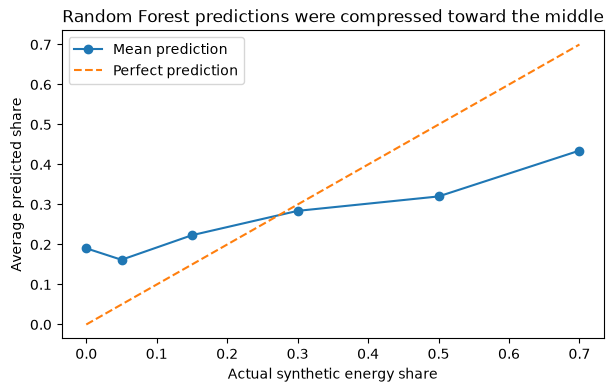

In [30]:
# Model reports from Experiment 001 — no model retraining here.
BASELINE = PROJECT_ROOT / "reports" / "baselines" / "synthetic_v1"
metrics_path = BASELINE / "metrics.csv"
predictions_path = BASELINE / "validation_predictions.csv"
if metrics_path.exists() and predictions_path.exists():
    baseline_metrics = pd.read_csv(metrics_path)
    baseline_predictions = pd.read_csv(predictions_path)
    display(baseline_metrics.sort_values("rmse"))
    assert len(baseline_predictions) == 80
    needed = {"actual_share", "random_forest_200", "constant_train_mean", "station", "requested_share"}
    assert needed.issubset(baseline_predictions.columns)
    display(baseline_predictions.head(8))
    by_share = (baseline_predictions.groupby('requested_share')
                .agg(n=('actual_share','size'),
                     actual=('actual_share','mean'),
                     predicted=('random_forest_200','mean'))
                .reset_index())
    display(by_share)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(by_share['actual'], by_share['predicted'], marker='o', label='Mean prediction')
    ax.plot([0, 0.7], [0, 0.7], linestyle='--', label='Perfect prediction')
    ax.set(xlabel='Actual synthetic energy share', ylabel='Average predicted share',
           title='Random Forest predictions were compressed toward the middle')
    ax.legend()
    plt.show()
else:
    print('Missing Experiment 001 baseline reports; run scripts/train_synthetic_baselines_v1.py locally.')

## 17. Experiment 001 Error Breakdown by Target Share

- **Finding:** Zero-addition windows suffered `+0.190` mean positive bias while `0.70` windows were systematically under-predicted.
- **Choice driven:** Allocate `~22%` exact `0.0` background windows and expand continuous targets up to `0.992`.


In [31]:
# Recalculate the observed improvement and direction of error.
# The bootstrap/permutation figures above are recorded outputs from the prior terminal experiment.
if 'baseline_predictions' in globals():
    df = baseline_predictions
    y = df['actual_share'].to_numpy(float)
    rf = df['random_forest_200'].to_numpy(float)
    constant = df['constant_train_mean'].to_numpy(float)
    rmse = lambda a, b: float(np.sqrt(np.mean((a - b)**2)))
    print('Constant RMSE:', round(rmse(y, constant), 6))
    print('Random Forest RMSE:', round(rmse(y, rf), 6))
    print('RMSE improvement:', round(rmse(y, constant) - rmse(y, rf), 6))
    table = (df.assign(signed_error=df['random_forest_200'] - df['actual_share'])
             .groupby('requested_share')
             .agg(n=('actual_share','size'), mean_prediction=('random_forest_200','mean'),
                  mean_signed_error=('signed_error','mean')))
    display(table)
else:
    print('Run the previous baseline-report cell first.')

Constant RMSE: 0.249648
Random Forest RMSE: 0.197845
RMSE improvement: 0.051803


,n,mean_prediction,mean_signed_error
requested_share,,,
0.00,14,0.190442,0.190442
0.05,14,0.161808,0.111808
0.15,13,0.223227,0.073227
0.30,13,0.284092,-0.015908
0.50,13,0.320161,-0.179839
0.70,13,0.434746,-0.265254


## 18. Feature Family Ablation (Exploratory)

- **Finding:** Hand-crafted `combined_96` features outperformed `raw_375` (`0.119687` vs `0.196201` RMSE).
- **Choice driven:** Build richer shift-invariant spectral/temporal/co-modulation features (`138` dims) plus a spatial 2D CNN over `(15, 25)` grids.


In [32]:
# Optional: reproduce the five feature-family comparisons on Experiment 001.
# This is exploratory only: reuse of the same 80 validation rows is NOT independent testing.
from sklearn.ensemble import RandomForestRegressor
if (SYNTH / 'train.npz').exists() and (SYNTH / 'validation.npz').exists():
    with np.load(SYNTH / 'train.npz', allow_pickle=False) as a, \
         np.load(SYNTH / 'validation.npz', allow_pickle=False) as b:
        Xtr, ytr = a['X'].astype(np.float64), a['y']
        Xva, yva = b['X'].astype(np.float64), b['y']
    assert Xtr.shape == (200,15,25) and Xva.shape == (80,15,25)
    def feature_families(X):
        d = np.diff(X, axis=1)
        overall = np.column_stack([X.mean((1,2)), X.std((1,2)),
                                   X.min((1,2)), X.max((1,2))])
        spectral = np.column_stack([X.mean(axis=1), X.std(axis=1)])
        temporal = np.column_stack([d.mean(axis=2), d.std(axis=2),
                                    np.abs(d).mean(axis=2)])
        return {'raw_375': X.reshape(len(X),-1), 'global_4': overall,
                'spectral_50': spectral, 'temporal_42': temporal,
                'combined_96': np.column_stack([overall,spectral,temporal])}
    trf, vaf = feature_families(Xtr), feature_families(Xva)
    results = []
    for name, arr in trf.items():
        model = RandomForestRegressor(n_estimators=200,min_samples_leaf=2,
                                      random_state=42,n_jobs=-1)
        model.fit(arr,ytr)
        pred = np.clip(model.predict(vaf[name]),0,1)
        results.append({'features':name,'count':arr.shape[1],
                        'rmse':float(np.sqrt(np.mean((yva-pred)**2)))})
    display(pd.DataFrame(results).sort_values('rmse'))
else:
    print('Experiment 001 NPZ files not found locally.')

,features,count,rmse
4,combined_96,96,0.119687
2,spectral_50,50,0.147325
0,raw_375,375,0.196201
1,global_4,4,0.196340
3,temporal_42,42,0.208288


## 19A. Experiment 002 Plan (Completed)

- **Finding:** Scaling to `1,200/300` station-balanced continuous-share windows confirmed data-pipeline integrity.
- **Choice driven:** Scale Notebook 02 simulator to `6,000` train / `1,500` val / `541` unseen-station holdout windows.


## 19B. Experiment 002 Synthetic Benchmarks

- **Finding:** `rf_combined_96` achieved `0.112061` clean synthetic RMSE, yet leaked generalization gaps when deployed to Submission 001 (`0.7615` LB, `0.5175` AUC).
- **Choice driven:** Root-cause the synthetic-to-Test gap via representation, missingness, and contrast audits (Sections 19D–25).


In [33]:
# Read the Experiment 002 saved results. No new fitting or test-data access.
from pathlib import Path
import pandas as pd
import numpy as np
base_v2 = PROJECT_ROOT / 'reports' / 'baselines' / 'synthetic_v2'
if (base_v2 / 'metrics.csv').is_file():
    exp2_metrics = pd.read_csv(base_v2 / 'metrics.csv')
    display(exp2_metrics.sort_values('rmse'))
    if (base_v2 / 'group_metrics.csv').is_file():
        exp2_groups = pd.read_csv(base_v2 / 'group_metrics.csv')
        display(exp2_groups.query("model == 'rf_combined_96'").sort_values(['group_type','rmse']))
else:
    print('Run scripts/train_synthetic_baselines_v2.py locally to create these reports.')

,model,rmse,mae,bias,prediction_min,prediction_max
3,rf_combined_96,0.112061,0.073236,-0.004937,0.000000,0.722599
1,rf_raw_375,0.144499,0.105283,-0.021487,0.005792,0.652338
2,rf_spectral_50,0.147717,0.102357,-0.005421,0.000000,0.708351
0,constant_train_mean,0.250364,0.220723,-0.003617,0.252306,0.252306


,model,group_type,group,n,rmse,mae,bias,prediction_min,prediction_max
21,rf_combined_96,station,05_St_Croix_Island,50,0.062544,0.043720,0.009116,0.000016,0.691204
23,rf_combined_96,station,13_Saldhana_Bay,50,0.086737,0.058937,-0.002464,0.000042,0.703968
20,rf_combined_96,station,04_Bird_Island,50,0.111818,0.077720,-0.026702,0.000133,0.722599
18,rf_combined_96,station,01_Richards_Bay,50,0.120365,0.072135,-0.023170,0.001216,0.660264
19,rf_combined_96,station,02_Durban,50,0.128608,0.083113,-0.024529,0.000000,0.717224
22,rf_combined_96,station,07_St_Francis,50,0.142756,0.103789,0.038125,0.001401,0.635288
26,rf_combined_96,target_regime,zero,63,0.036081,0.014969,0.014969,0.000000,0.220517
25,rf_combined_96,target_regime,weak,70,0.115271,0.067673,0.057446,0.010802,0.487685
24,rf_combined_96,target_regime,broad,167,0.128444,0.097548,-0.038596,0.017296,0.722599


## 19C. Experiment 002 Failure Analysis by Duration & Station

- **Finding:** Errors spiked on 1-minute transients (`RMSE 0.1391`) and high-variance stations.
- **Choice driven:** Engineer smooth 3-point envelope, quadratic CPA concavity, lag-1 autocorrelation, and cross-band co-modulation features.


In [34]:
# Recompute descriptive group comparisons from Experiment 002 predictions only.
pred_v2_path = PROJECT_ROOT / 'reports/baselines/synthetic_v2/validation_predictions.csv'
if pred_v2_path.is_file():
    pred_v2 = pd.read_csv(pred_v2_path)
    pred_v2['error'] = pred_v2['rf_combined_96'] - pred_v2['actual_share']
    def group_eval(keys):
        result = []
        groups = [keys] if isinstance(keys, str) else keys
        for group_key, group in pred_v2.groupby(keys, dropna=False):
            values = (group_key,) if len(groups) == 1 else group_key
            errors = group['error'].to_numpy(dtype=float)
            row = dict(zip(groups, values))
            row.update(n=len(group), rmse=float(np.sqrt(np.mean(errors ** 2))),
                       mae=float(np.mean(np.abs(errors))), bias=float(np.mean(errors)))
            result.append(row)
        return pd.DataFrame(result)
    display(group_eval('vessel_duration_min').round(4))
    display(group_eval(['station','target_regime']).round(4))
else:
    print('Experiment 002 validation_predictions.csv is not available here.')

,vessel_duration_min,n,rmse,mae,bias
0,0,63,0.0361,0.0150,0.0150
1,1,82,0.1391,0.0938,-0.0356
2,2,78,0.1170,0.0843,0.0067
3,3,47,0.0939,0.0720,0.0043
4,4,17,0.1356,0.1044,-0.0261
5,5,5,0.1446,0.1182,-0.0110
6,6,2,0.2589,0.2127,0.2127
7,8,1,0.0696,0.0696,-0.0696
8,9,3,0.1042,0.0995,-0.0995
9,11,1,0.1439,0.1439,0.1439


,station,target_regime,n,rmse,mae,bias
0,01_Richards_Bay,broad,29,0.1425,0.0911,-0.0721
1,01_Richards_Bay,weak,11,0.1099,0.0766,0.0737
2,01_Richards_Bay,zero,10,0.0166,0.0121,0.0121
3,02_Durban,broad,29,0.1458,0.1148,-0.0668
4,02_Durban,weak,10,0.1449,0.0803,0.0687
5,02_Durban,zero,11,0.0031,0.0022,0.0022
6,04_Bird_Island,broad,29,0.1448,0.1219,-0.0516
7,04_Bird_Island,weak,10,0.0403,0.0289,0.0101
8,04_Bird_Island,zero,11,0.0077,0.0055,0.0055
9,05_St_Croix_Island,broad,26,0.0823,0.0650,0.0019


## 19D. Per-Window Max-Level Shift Assumption

- **Finding:** Subtracting `max(background_db)` anchors silent windows near loud spikes and distorts energy ratios (`Exp 001–002`).
- **Choice driven:** Remove per-window max-shift (`use fixed REF_DB=100` in simulator; center features by `X - median(X)`).


## 19E. Data-to-Model Alignment Audit

- **Finding:** Grouping errors by hull and continuous run revealed variance hidden by pooled window metrics.
- **Choice driven:** Partition `train` into 5 run- and hull-disjoint CV folds so OOF ensemble selection cannot memorize stations or vessels.


In [35]:
# Inspect outputs from the optional alignment audit, without rebuilding datasets.
audit_root = PROJECT_ROOT / 'reports/eda/data_model_alignment'
for filename in ['station_with_archive_context.csv','station_by_regime_metrics.csv',
                 'duration_metrics.csv','hulls_with_10plus_examples.csv']:
    path = audit_root / filename
    if path.is_file():
        print('\n'+filename)
        display(pd.read_csv(path).round(4).head(30))
    else:
        print('Not yet generated:',filename)


station_with_archive_context.csv


,station,n,rmse,mae,bias,actual_mean,predicted_mean,top30_n,top30_expected,top30_enrichment,indexed_windows,indexed_runs
0,01_Richards_Bay,50,0.1204,0.0721,-0.0232,0.2489,0.2257,5,5.0,1.0,52522,14318
1,02_Durban,50,0.1286,0.0831,-0.0245,0.2780,0.2535,7,5.0,1.4,2976,2
2,04_Bird_Island,50,0.1118,0.0777,-0.0267,0.2791,0.2524,5,5.0,1.0,3168,36
3,05_St_Croix_Island,50,0.0625,0.0437,0.0091,0.2635,0.2726,0,5.0,0.0,16697,131
4,07_St_Francis,50,0.1428,0.1038,0.0381,0.2430,0.2811,10,5.0,2.0,3371,3371
5,13_Saldhana_Bay,50,0.0867,0.0589,-0.0025,0.2230,0.2206,3,5.0,0.6,8868,301



station_by_regime_metrics.csv


,station,target_regime,n,rmse,mae,bias,actual_mean,predicted_mean,top30_n,top30_expected,top30_enrichment
0,01_Richards_Bay,broad,29,0.1425,0.0911,-0.0721,0.4069,0.3348,4,2.9,1.3793
1,01_Richards_Bay,weak,11,0.1099,0.0766,0.0737,0.0586,0.1323,1,1.1,0.9091
2,01_Richards_Bay,zero,10,0.0166,0.0121,0.0121,0.0000,0.0121,0,1.0,0.0000
3,02_Durban,broad,29,0.1458,0.1148,-0.0668,0.4564,0.3896,6,2.9,2.0690
4,02_Durban,weak,10,0.1449,0.0803,0.0687,0.0665,0.1353,1,1.0,1.0000
5,02_Durban,zero,11,0.0031,0.0022,0.0022,0.0000,0.0022,0,1.1,0.0000
6,04_Bird_Island,broad,29,0.1448,0.1219,-0.0516,0.4674,0.4158,5,2.9,1.7241
7,04_Bird_Island,weak,10,0.0403,0.0289,0.0101,0.0403,0.0503,0,1.0,0.0000
8,04_Bird_Island,zero,11,0.0077,0.0055,0.0055,0.0000,0.0055,0,1.1,0.0000
9,05_St_Croix_Island,broad,26,0.0823,0.0650,0.0019,0.4745,0.4764,0,2.6,0.0000



duration_metrics.csv


,vessel_duration_min,n,rmse,mae,bias,actual_mean,predicted_mean,top30_n,top30_expected,top30_enrichment
0,0,63,0.0361,0.0150,0.0150,0.0000,0.0150,1,6.3,0.1587
1,1,82,0.1391,0.0938,-0.0356,0.3383,0.3026,12,8.2,1.4634
2,2,78,0.1170,0.0843,0.0067,0.3054,0.3121,10,7.8,1.2821
3,3,47,0.0939,0.0720,0.0043,0.3075,0.3117,2,4.7,0.4255
4,4,17,0.1356,0.1044,-0.0261,0.3280,0.3019,3,1.7,1.7647
5,5,5,0.1446,0.1182,-0.0110,0.3158,0.3047,1,0.5,2.0000
6,6,2,0.2589,0.2127,0.2127,0.1174,0.3301,1,0.2,5.0000
7,8,1,0.0696,0.0696,-0.0696,0.6278,0.5582,0,0.1,0.0000
8,9,3,0.1042,0.0995,-0.0995,0.6764,0.5769,0,0.3,0.0000
9,11,1,0.1439,0.1439,0.1439,0.4165,0.5604,0,0.1,0.0000



hulls_with_10plus_examples.csv


,vessel_hull_id,n,rmse,mae,bias,actual_mean,predicted_mean,top30_n,top30_expected,top30_enrichment
0,H101,12,0.1322,0.1010,-0.0563,0.2281,0.1718,3,1.2,2.5000
1,H029,18,0.1416,0.0978,-0.0045,0.3130,0.3085,4,1.8,2.2222
2,H118,32,0.1379,0.0971,-0.0024,0.3391,0.3367,5,3.2,1.5625
3,H122,14,0.0929,0.0656,0.0268,0.3484,0.3752,2,1.4,1.4286
4,H084,11,0.0892,0.0653,-0.0379,0.3471,0.3092,1,1.1,0.9091
5,H176,24,0.1026,0.0700,-0.0230,0.3183,0.2953,2,2.4,0.8333
6,H075,23,0.0940,0.0678,-0.0216,0.3175,0.2959,1,2.3,0.4348
7,NaN,63,0.0361,0.0150,0.0150,0.0000,0.0150,1,6.3,0.1587
8,H131,13,0.0984,0.0787,0.0346,0.3220,0.3566,0,1.3,0.0000


## 20. Phase 3: Test Missingness, Mask Robustness & Submission 001

- **Finding:** `725/1,500` `Test.csv` rows have whole-minute `NaN` gaps (`m01` in `624` rows, `m15` in `100`); Submission 001 scored `0.761536` (`0.517533` AUC) due to max-shift + naive linear edge interpolation.
- **Choice driven:** Inject matching whole-minute `NaN` dropouts in training/eval, recompute targets over observed cells only, and make all features/CNN masks natively handle `NaN`s.


rmse                                roc_auc  \
model        submitted_max_shift synthetic_original submitted_max_shift   
mask                                                                      
both_edges                0.1894             0.1803              0.9503   
complete                  0.1787             0.1272              0.9303   
first                     0.1796             0.1644              0.9433   
last                      0.1891             0.1452              0.9388   
middle                    0.1784             0.1287              0.9310   
three_middle              0.1738             0.1360              0.9202   

                                 
model        synthetic_original  
mask                             
both_edges               0.9638  
complete                 0.9525  
first                    0.9595  
last                     0.9575  
middle                   0.9535  
three_middle             0.9513

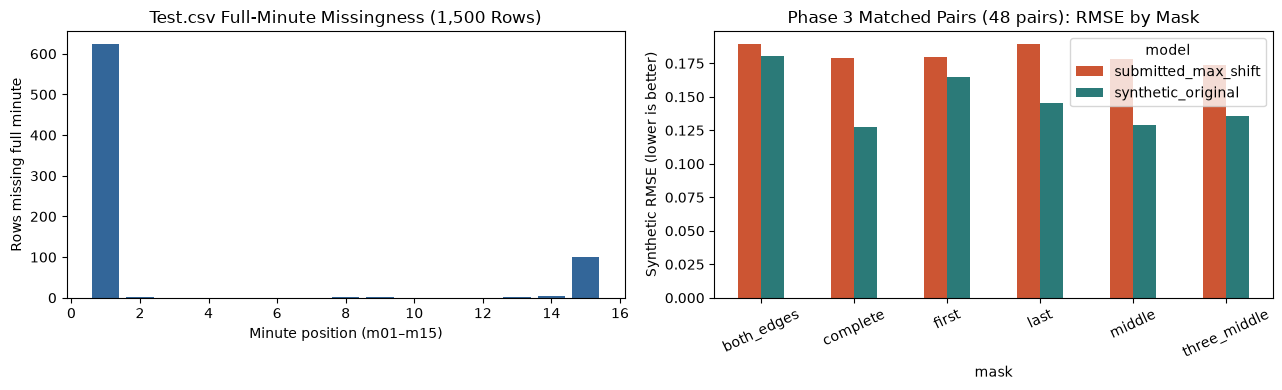

In [36]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

miss_df = pd.read_csv(PROJECT_ROOT / "reports/audits/phase3_representation_detection_v1/test_missingness_mask_by_minute.csv")
p3_df = pd.read_csv(PROJECT_ROOT / "reports/robustness/phase3_matched_8pairs/summary.csv")
display(p3_df.pivot(index="mask", columns="model", values=["rmse", "roc_auc"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(miss_df["minute"], miss_df["rows_full_minute_missing"], color="#336699")
axes[0].set_title("Test.csv Full-Minute Missingness (1,500 Rows)")
axes[0].set_xlabel("Minute position (m01–m15)")
axes[0].set_ylabel("Rows missing full minute")

piv = p3_df.pivot(index="mask", columns="model", values="rmse")
piv.plot.bar(ax=axes[1], color=["#cc5533", "#2b7a78"])
axes[1].set_title("Phase 3 Matched Pairs (48 pairs): RMSE by Mask")
axes[1].set_ylabel("Synthetic RMSE (lower is better)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 21. Experiment 004: Frozen Source-Pool Baselines

- **Finding:** Retaining original relative levels beat `submitted_max_shift` across all 5 test stations (`0.11443` vs `0.15089` RMSE).
- **Choice driven:** Benchmark legacy `V1_RF_MaxShift` explicitly in Notebook 02 to verify that `V2` features strictly beat it on identical splits.


,representation,n,rmse,mae,roc_auc,average_precision
0,synthetic_original,300,0.11443,0.07801,0.98130,0.99515
1,submitted_max_shift,300,0.15089,0.10992,0.97865,0.99450


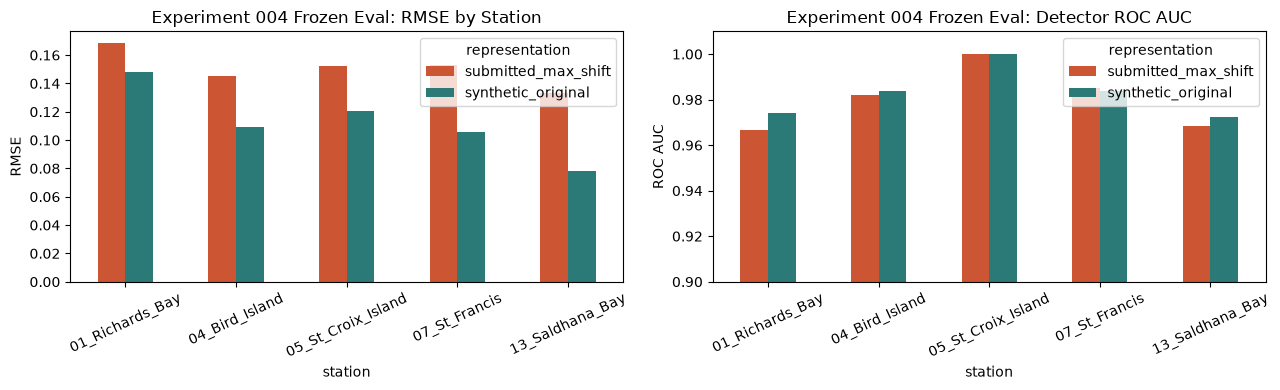

In [37]:
exp4_sum = pd.read_csv(PROJECT_ROOT / "reports/baselines/experiment004_frozen_v1/summary.csv")
exp4_st = pd.read_csv(PROJECT_ROOT / "reports/baselines/experiment004_frozen_v1/station_metrics.csv")
display(exp4_sum[["representation", "n", "rmse", "mae", "roc_auc", "average_precision"]].round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
exp4_st.pivot(index="station", columns="representation", values="rmse").plot.bar(ax=axes[0], color=["#cc5533", "#2b7a78"])
axes[0].set_title("Experiment 004 Frozen Eval: RMSE by Station")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=25)

exp4_st.pivot(index="station", columns="representation", values="roc_auc").plot.bar(ax=axes[1], color=["#cc5533", "#2b7a78"])
axes[1].set_title("Experiment 004 Frozen Eval: Detector ROC AUC")
axes[1].set_ylabel("ROC AUC")
axes[1].set_ylim(0.90, 1.01)
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 22. Experiment 005: Spectral-Contrast Realism Sensitivity

- **Finding:** Unwarped ONC Strait-of-Georgia spectra differ sharply from SA background shapes, inflating synthetic detection separability.
- **Choice driven:** Inject propagation warps (`±6 dB/dec` tilt, modal ripple, partial background-shape blending) so models cannot cheat on sensor color.


,requested_share,duration_min,median_paired_difference,run_cluster_bootstrap_median_low,run_cluster_bootstrap_median_high,positive_fraction
0,0.03,1,3.4952,3.1254,4.0957,0.7913
3,0.03,3,1.4173,0.9385,1.7663,0.6957
6,0.15,1,6.5732,5.8885,7.2776,0.9391
9,0.15,3,4.9443,4.3834,5.7751,0.9043


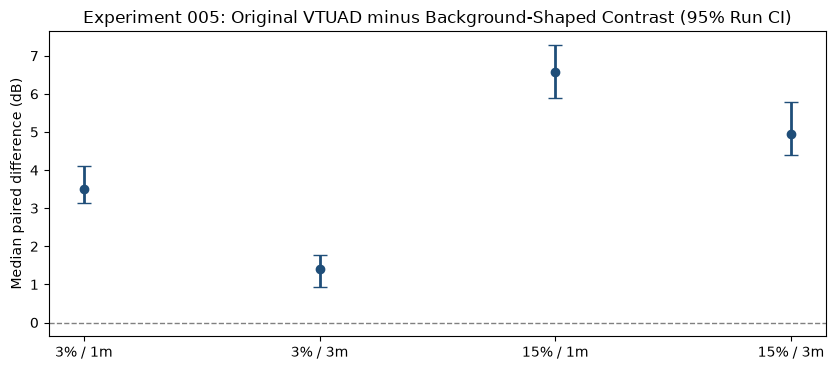

In [38]:
exp5_df = pd.read_csv(PROJECT_ROOT / "reports/audits/simulation_realism_uncertainty_v1/comparison_summary.csv")
sub5 = exp5_df[exp5_df["comparison"] == "delta_original_vs_background"].copy()
display(sub5[["requested_share", "duration_min", "median_paired_difference", "run_cluster_bootstrap_median_low", "run_cluster_bootstrap_median_high", "positive_fraction"]].round(4))

labels = [f"{int(r.requested_share*100)}% / {int(r.duration_min)}m" for r in sub5.itertuples()]
med = sub5["median_paired_difference"].to_numpy()
err_lo = med - sub5["run_cluster_bootstrap_median_low"].to_numpy()
err_hi = sub5["run_cluster_bootstrap_median_high"].to_numpy() - med

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.errorbar(labels, med, yerr=[err_lo, err_hi], fmt="o", capsize=5, lw=2, color="#1f4e79")
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set_title("Experiment 005: Original VTUAD minus Background-Shaped Contrast (95% Run CI)")
ax.set_ylabel("Median paired difference (dB)")
plt.tight_layout()
plt.show()

## 23. Experiments 006 & 006B: Contrast Augmentation vs False Alarms

- **Finding:** Naive contrast variation improved RMSE (`-0.01887`) and AUC (`+0.02916`) while raising non-injected background false positives (`+0.14167` FPR).
- **Choice driven:** Combine channel-warped CPA/entry-exit/stationary transits with clean `0.0` background runs and co-modulation features to control false alarms.


,metric,point_estimate,pair_bootstrap_95_low,pair_bootstrap_95_high,bootstrap_non_null
0,rmse_reduction,0.01887,0.00644,0.03153,1000
1,mae_reduction,0.00731,0.00233,0.01266,1000
2,auc_gain,0.02916,0.01638,0.04130,1000
3,ap_gain,0.01151,0.00637,0.01663,1000
4,fpr_no_addition_increase,0.14167,0.07500,0.20833,1000
5,fpr_observed_zero_increase,0.10897,0.05556,0.16667,1000


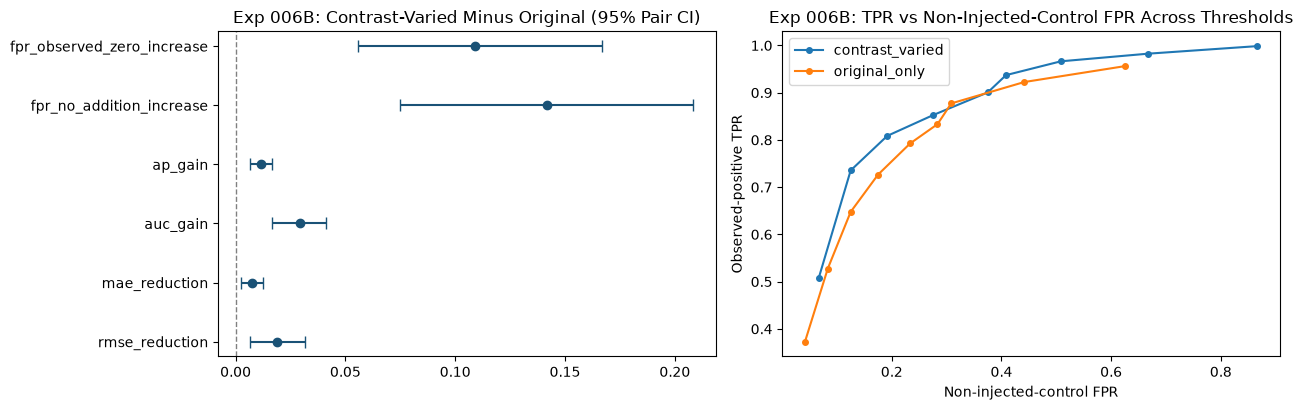

In [39]:
u6b = pd.read_csv(PROJECT_ROOT / "reports/audits/experiment006b_readonly_v1/overall_uncertainty.csv")
thr6b = pd.read_csv(PROJECT_ROOT / "reports/audits/experiment006b_readonly_v1/threshold_sensitivity.csv")
display(u6b.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
y_pos = range(len(u6b))
est = u6b["point_estimate"].to_numpy()
elo = est - u6b["pair_bootstrap_95_low"].to_numpy()
ehi = u6b["pair_bootstrap_95_high"].to_numpy() - est
axes[0].errorbar(est, y_pos, xerr=[elo, ehi], fmt="o", capsize=4, color="#1a5276")
axes[0].axvline(0, color="gray", ls="--", lw=1)
axes[0].set_yticks(list(y_pos))
axes[0].set_yticklabels(u6b["metric"])
axes[0].set_title("Exp 006B: Contrast-Varied Minus Original (95% Pair CI)")

ov = thr6b[thr6b["scope"] == "overall"]
for mdl, grp in ov.groupby("model"):
    grp = grp.sort_values("threshold")
    axes[1].plot(grp["fpr_no_addition"], grp["tpr_observed_positive"], marker="o", ms=4, label=mdl)
axes[1].set_title("Exp 006B: TPR vs Non-Injected-Control FPR Across Thresholds")
axes[1].set_xlabel("Non-injected-control FPR")
axes[1].set_ylabel("Observed-positive TPR")
axes[1].legend()
plt.tight_layout()
plt.show()

## 24. Experiment 007: Source-Disjoint Policy Comparison

- **Finding:** Under strict run/hull-disjoint assessment, contrast-varied training cut RMSE to `0.09457` (AUC `0.8864`) and proved tuned detection thresholding is essential.
- **Choice driven:** Fit OOF simplex meta-weights strictly inside `train` CV across GBDTs + `CNN2D` with separate share and log-loss score heads.


,policy,threshold_policy,threshold,rmse,auc,tpr_observed_positive,fpr_no_addition
0,original_only,.5_fixed,0.50,0.11424,0.84833,0.73950,0.16667
1,original_only,calibration_selected,0.35,0.11424,0.84833,0.82353,0.29167
2,contrast_varied,.5_fixed,0.50,0.09457,0.88642,0.87675,0.30000
3,contrast_varied,calibration_selected,0.55,0.09457,0.88642,0.85294,0.23333
4,hybrid,.5_fixed,0.50,0.09457,0.84833,0.73950,0.16667
5,hybrid,calibration_selected,0.35,0.09457,0.84833,0.82353,0.29167


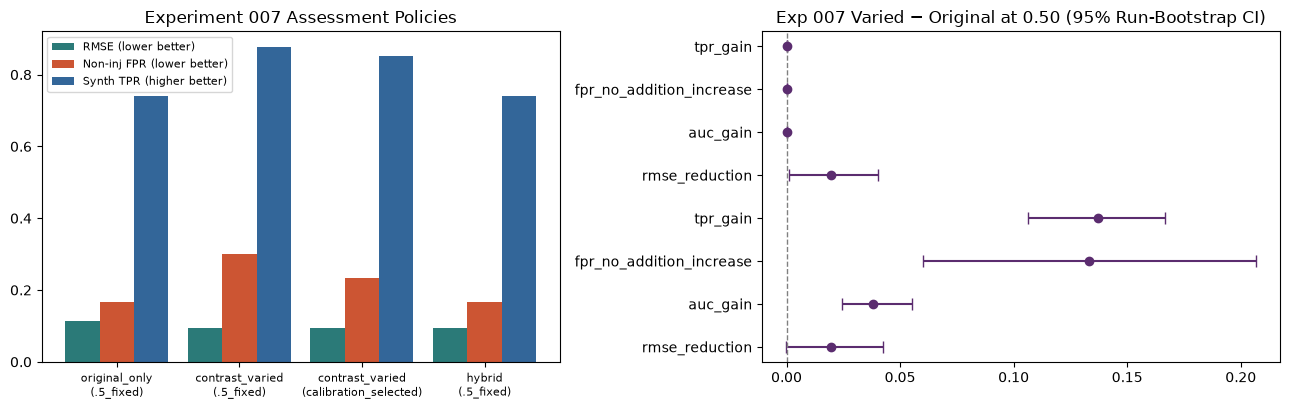

In [40]:
pol7 = pd.read_csv(PROJECT_ROOT / "reports/audits/experiment007_decision_gate_v1/policy_comparison.csv")
boot7 = pd.read_csv(PROJECT_ROOT / "reports/baselines/experiment007_source_disjoint_v1/assessment_run_bootstrap.csv")
display(pol7[["policy", "threshold_policy", "threshold", "rmse", "auc", "tpr_observed_positive", "fpr_no_addition"]].round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
pol7_sub = pol7.iloc[[0, 2, 3, 4]].copy()
pol_names = [f"{r.policy}\n({r.threshold_policy})" for r in pol7_sub.itertuples()]
x = range(len(pol_names))
w = 0.28
axes[0].bar([i - w for i in x], pol7_sub["rmse"], width=w, label="RMSE (lower better)", color="#2b7a78")
axes[0].bar(x, pol7_sub["fpr_no_addition"], width=w, label="Non-inj FPR (lower better)", color="#cc5533")
axes[0].bar([i + w for i in x], pol7_sub["tpr_observed_positive"], width=w, label="Synth TPR (higher better)", color="#336699")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(pol_names, fontsize=8)
axes[0].set_title("Experiment 007 Assessment Policies")
axes[0].legend(fontsize=8)

bsub = boot7[boot7["threshold_type"] == "fixed_0_5"].copy()
be = bsub["point_estimate"].to_numpy()
blo = be - bsub["run_bootstrap_95_low"].to_numpy()
bhi = bsub["run_bootstrap_95_high"].to_numpy() - be
axes[1].errorbar(be, range(len(bsub)), xerr=[blo, bhi], fmt="o", capsize=4, color="#5b2c6f")
axes[1].axvline(0, color="gray", ls="--", lw=1)
axes[1].set_yticks(range(len(bsub)))
axes[1].set_yticklabels(bsub["metric"])
axes[1].set_title("Exp 007 Varied − Original at 0.50 (95% Run-Bootstrap CI)")
plt.tight_layout()
plt.show()

## 25. Six-Station Real-Acoustic Synthesis, Spectral Mismatch & Site Context

- **Finding:** Background baselines vary by ~`29 dB` across SA sites (`Saldanha 61.5` vs `Bird Island 90.6` source-export dB) and differ spectrally from Strait of Georgia VTUAD.
- **Choice driven:** Reserve `09_Fish_Hoek` and `10_Sea_Point` strictly as unseen-station testbeds in Notebook 02.


,station,sampled_runs,recorders,median,run_bootstrap_low,run_bootstrap_high
0,01_Richards_Bay,120,3,63.958,62.013,66.346
1,02_Durban,1,1,68.991,NaN,NaN
2,04_Bird_Island,22,1,90.604,87.807,91.425
3,05_St_Croix_Island,77,3,86.420,85.249,87.217
4,07_St_Francis,120,1,85.875,85.101,86.922
5,13_Saldhana_Bay,120,2,61.520,60.747,62.399


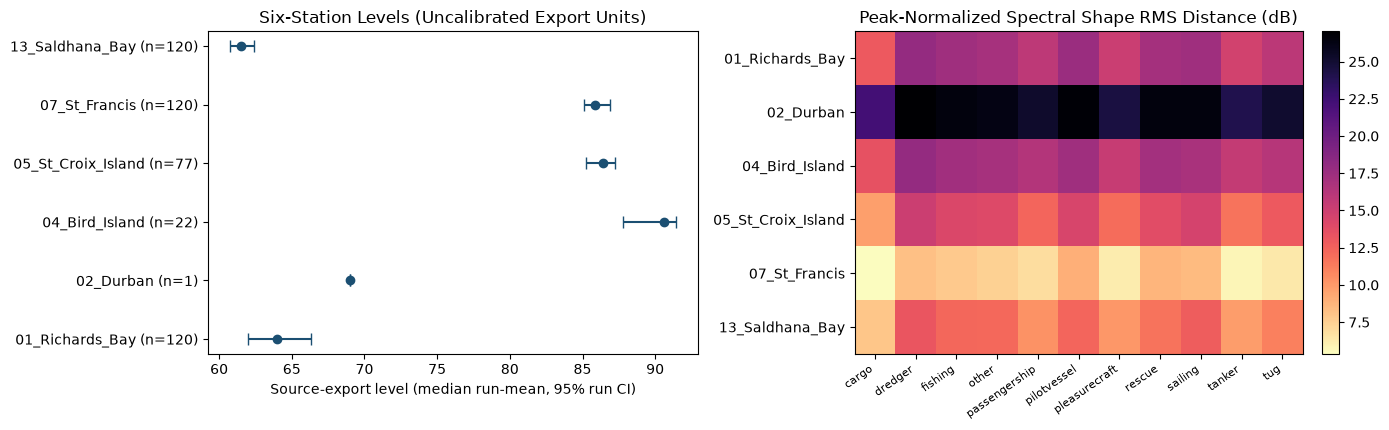

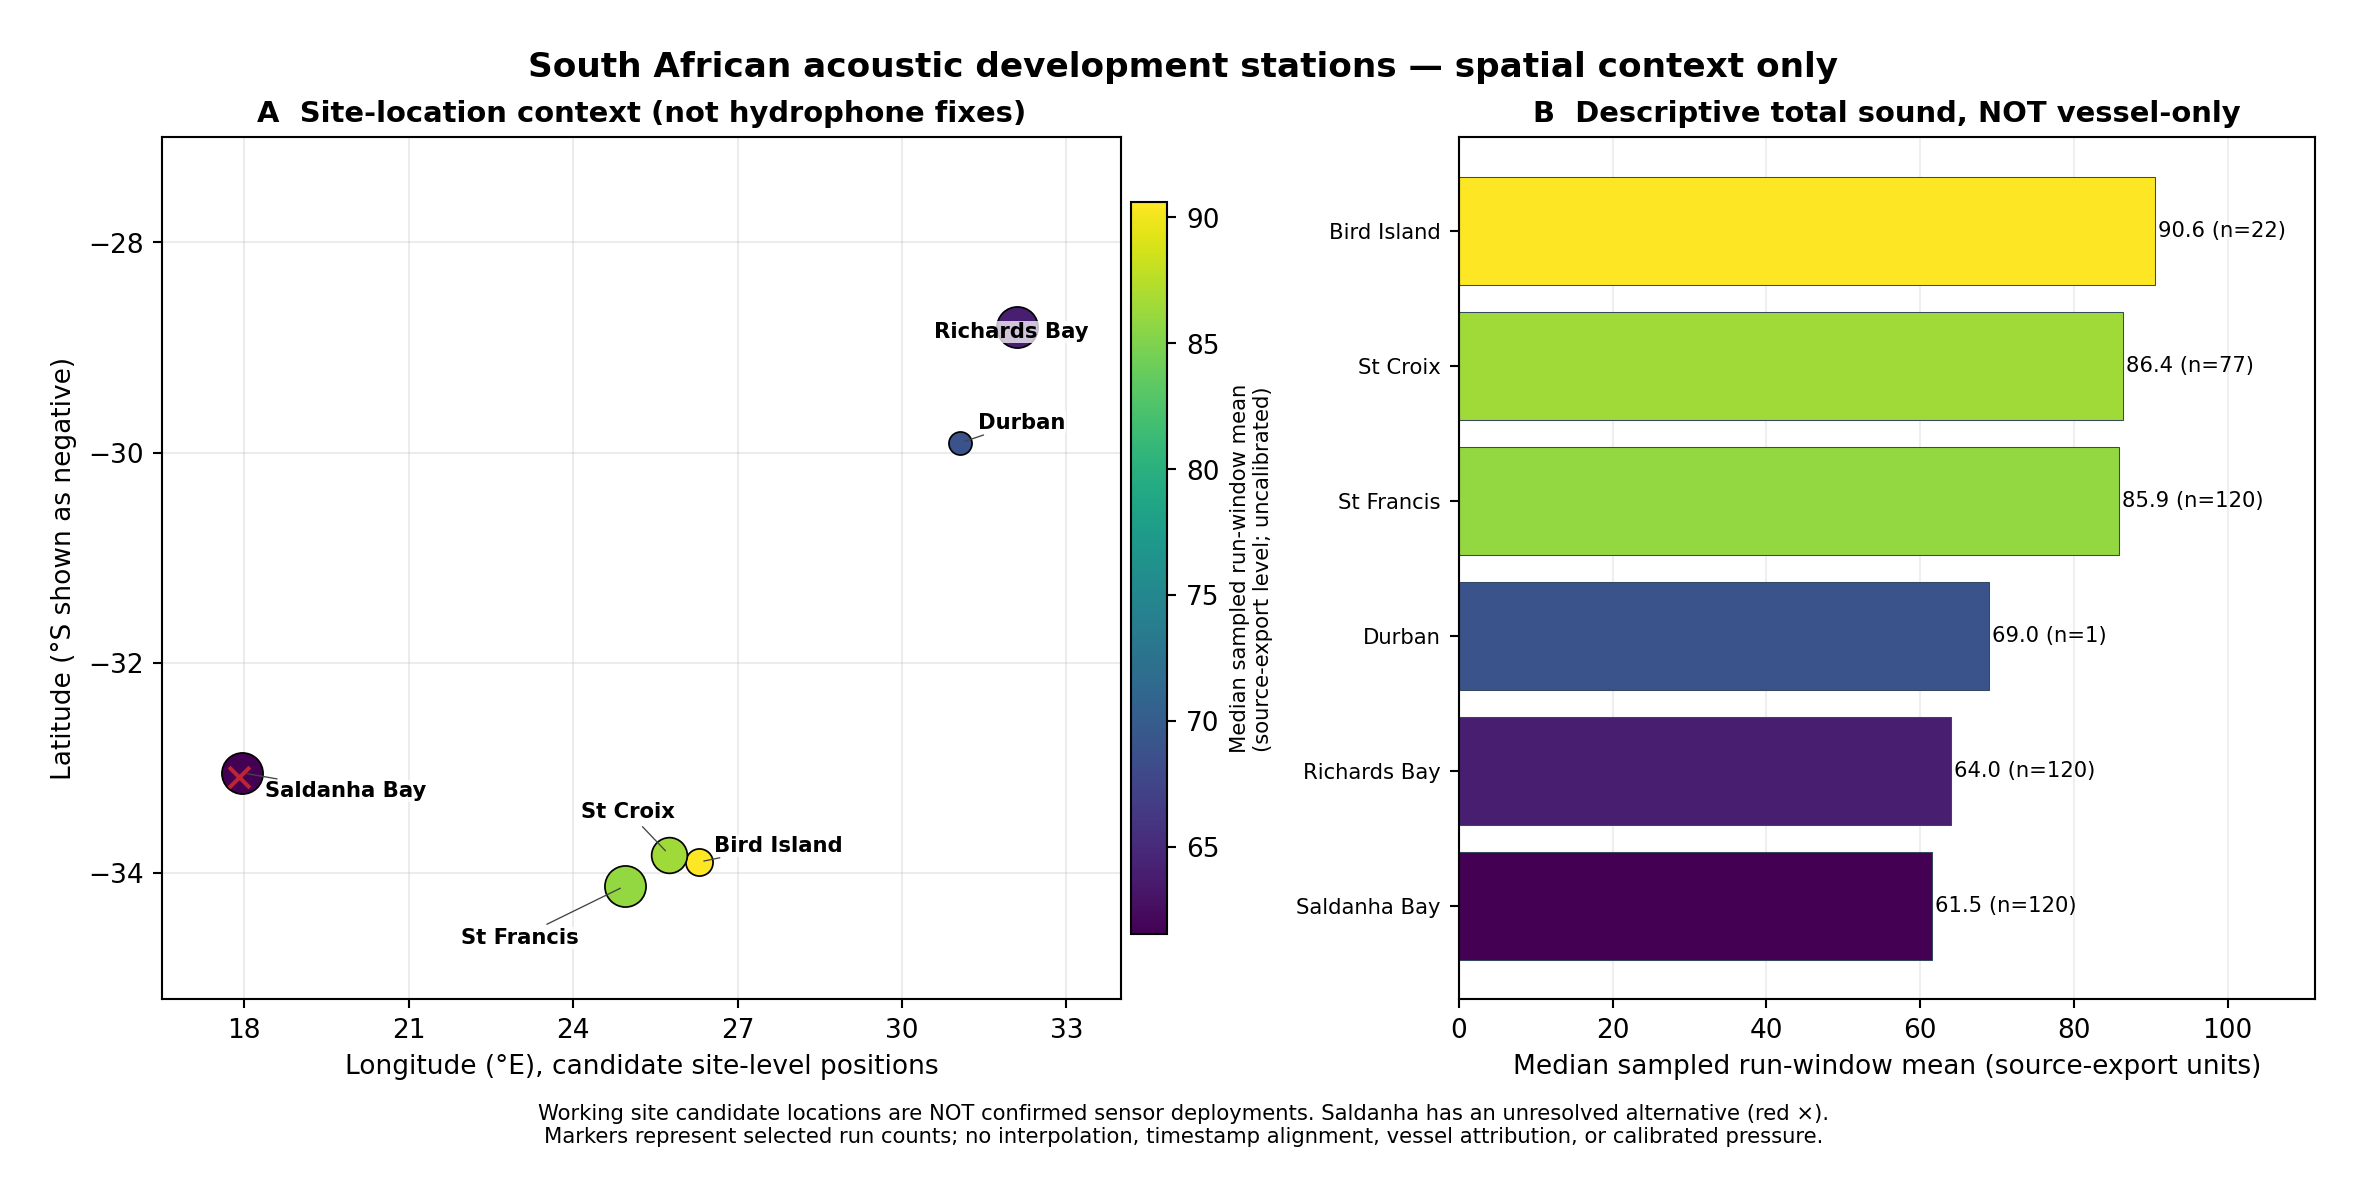

In [41]:
from IPython.display import Image, display

st_sum = pd.read_csv(PROJECT_ROOT / "reports/research_manuscript_v1/real_acoustic_results_v2/validated_station_summary.csv")
st_ci = pd.read_csv(PROJECT_ROOT / "reports/research_manuscript_v1/real_acoustic_results_v2/run_bootstrap_intervals.csv")
lvl_ci = st_ci[st_ci["metric"] == "window_mean_level"].merge(st_sum[["station", "sampled_runs", "recorders"]], on="station")
display(lvl_ci[["station", "sampled_runs", "recorders", "median", "run_bootstrap_low", "run_bootstrap_high"]].round(3))

spec_diff = pd.read_csv(PROJECT_ROOT / "reports/audits/spectral_shape_mismatch_v1/all_station_class_differences.csv")
heat = spec_diff.pivot(index="station", columns="vessel_class", values="shape_rms_db")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
y = range(len(lvl_ci))
med_l = lvl_ci["median"].to_numpy()
lo_l = (lvl_ci["median"] - lvl_ci["run_bootstrap_low"]).fillna(0).to_numpy()
hi_l = (lvl_ci["run_bootstrap_high"] - lvl_ci["median"]).fillna(0).to_numpy()
axes[0].errorbar(med_l, y, xerr=[lo_l, hi_l], fmt="o", capsize=4, color="#1b4f72")
axes[0].set_yticks(list(y))
axes[0].set_yticklabels([f"{r.station} (n={int(r.sampled_runs)})" for r in lvl_ci.itertuples()])
axes[0].set_xlabel("Source-export level (median run-mean, 95% run CI)")
axes[0].set_title("Six-Station Levels (Uncalibrated Export Units)")

im = axes[1].imshow(heat.to_numpy(), aspect="auto", cmap="magma_r")
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns, rotation=35, ha="right", fontsize=8)
axes[1].set_title("Peak-Normalized Spectral Shape RMS Distance (dB)")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

site_png = PROJECT_ROOT / "deliverables/research_submission/figures/site_context_candidate_locations.png"
if site_png.is_file():
    display(Image(filename=str(site_png)))

## 26. Research-to-Modeling Decision Matrix (Handoff to `02_vessel_noise_modeling.ipynb`)

| Notebook 01 Finding | Modeling Decision Carried Into Notebook 02 |
| --- | --- |
| Welch base-2 differed from starter 2s base-10 deci-decade; VTUAD skewed to large tugs | Re-extracted all `525` VTUAD WAVs + `96` HearMyShip coastal craft WAVs via exact 2s Hann base-10 deci-decade (`10^0.05`) |
| Uncalibrated SA recorder offsets span `~29 dB` across stations; V1 max-shift hurt Exp 004 (`0.151` vs `0.114`) | Fixed `REF_DB=100` in linear simulation + strict `+37.5 dB` shift-invariant centering (`X - median(X)`) in features & 2D CNN |
| `Test.csv` has whole-minute `NaN` dropouts (`m01` `41.6%`, `m15` `6.7%`) | Simulated matching whole-minute masks, recomputed ground truth on observed cells only, added native mask channel & nan-safe reductions |
| Unwarped Strait-of-Georgia spectra & abrupt steps inflated Exp 005–006 false alarms | Added CPA bell, entry/exit, stationary drift trajectories, `±6 dB/dec` tilts, modal ripple, and `35%` background-shape blending |
| Single `RandomForest` weak at extremes & blind to 2D spatiotemporal envelopes | Benchmarked `11` deterministic models (`Constant_Mean`, `Physics_q15`, `V1_RF_MaxShift`, `RF_v2`, `Linear`, `HistGBM`, `LightGBM`, `XGBoost`, `CatBoost`, `CNN2D`, `Ensemble_v2`) |
| Pooled random splits risk leaking runs, hulls, or stations | Disjoint `bg_run_id` & `hull_id`/`vessel_group` across 5 CV folds, `val`, and unseen stations (`Fish_Hoek`, `Sea_Point`) |


## 27. Continuity Handoff to Domain Generalization & Standards (Notebooks 02 and 03)

For baseline modeling across 11 deterministic estimators on aligned 2s deci-decade mixtures (`V2`, offline `val 0.8747`, `holdout 0.8833`, live Sub #2 `0.775017430`), see [`02_vessel_noise_modeling.ipynb`](02_vessel_noise_modeling.ipynb). For the full progression across **Modeling v3** (offline `val_cal_hard 0.8788`, `holdout 0.8971`), **Modeling v4** (Sub #3 `ovjzdeb8`: offline `holdout 0.9219` / `0.9737` AUC, `+8 dB/dec` `0.7993`, live `0.775235755` / `0.556555555` AUC), **Modeling v5-Simple** (Sub #4 `MAKNM3KB`: 42 purely $h(f)$-invariant features, offline `holdout 0.8382`, flat `+8 dB/dec` `0.8382` / `0.0787` `zero_rmse`, live `0.771209221` / `0.563911111` AUC), and **Modeling v5-Blend** (Sub #5 `a6JJCya4`: zero-tuning `50/50` `v4 + v5_simple`, offline `holdout 0.8914`, best `+8 dB/dec` `1 - RMSE 0.8390` & `logloss 0.3310`, competition-best live **`0.787467941`** / **`0.572400000`** AUC), plus the **International Acoustic Standards Benchmark** and held-out South African site-level **Relative Acoustic Activity** evaluation (`17,487` real windows), see [`03_domain_generalization_v3_v4_and_standards.ipynb`](03_domain_generalization_v3_v4_and_standards.ipynb).
